# Определение токсичных комментариев методами машинного обучения

Полностью воспроизводимое исследование на официальном наборе **Jigsaw Toxic Comment Classification Challenge**.

В notebook выполнены:

1. проверка источника и структуры реального набора данных;
2. аудит пропусков, дубликатов и баланса классов;
3. исследование длин, частот слов и совместной встречаемости меток;
4. единое стратифицированное разбиение 70/15/15 и контроль утечки;
5. три варианта предобработки текста;
6. Bag of Words + Naive Bayes, TF-IDF + Logistic Regression и Linear SVM;
7. эксперименты с TF-IDF, параметром `C` и порогом классификации;
8. ROC/PR-кривые, матрицы ошибок и анализ реальных FP/FN;
9. готовая реализация fine-tuning DistilBERT, включаемая отдельно;
10. сохранение моделей, метрик, графиков и пересборка Word-отчёта.

> Набор содержит грубую и оскорбительную лексику. В notebook выводятся только необходимые короткие фрагменты.

## 1. Постановка исследования

**Цель:** построить и сравнить воспроизводимые модели бинарного определения токсичности комментариев.

**Объект:** англоязычные комментарии Wikipedia из соревнования Jigsaw.

**Целевая переменная:** `toxic` (`1` — токсичный комментарий, `0` — нетоксичный).

**Основные гипотезы:**

- TF-IDF с линейным классификатором превзойдёт простой Bag of Words + Naive Bayes;
- умеренная нормализация текста окажется полезнее агрессивной очистки;
- выбор порога на validation улучшит баланс Precision и Recall при дисбалансе классов;
- трансформер потенциально лучше учитывает контекст, но требует существенно больше ресурсов.

## 2. Окружение и надёжное определение корня проекта

Notebook можно открывать как из корня проекта, так и непосредственно из папки `notebooks/`.
Код ищет каталог с `src/toxicity` и `config/default.yaml` среди родительских директорий.
При нестандартном размещении путь можно задать переменной окружения `TOXICITY_PROJECT_ROOT`.

In [1]:
from pathlib import Path
import importlib.util
import json
import os
import platform
import sys
import warnings
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display


def find_project_root(start: Path | None = None) -> Path:
    # Найти корень проекта независимо от текущего каталога Jupyter.
    starts: list[Path] = []
    env_root = os.environ.get("TOXICITY_PROJECT_ROOT")
    if env_root:
        starts.append(Path(env_root).expanduser().resolve())
    starts.append((start or Path.cwd()).resolve())

    checked: list[Path] = []
    for base in starts:
        for candidate in (base, *base.parents):
            if candidate in checked:
                continue
            checked.append(candidate)
            if (
                (candidate / "src" / "toxicity" / "__init__.py").is_file()
                and (candidate / "config" / "default.yaml").is_file()
            ):
                return candidate

    common_location = Path.home() / "Documents" / "ChatGPT" / "курсовая по nlp"
    if (
        (common_location / "src" / "toxicity" / "__init__.py").is_file()
        and (common_location / "config" / "default.yaml").is_file()
    ):
        return common_location.resolve()

    locations = "\n".join(f"- {path}" for path in checked)
    raise RuntimeError(
        "Не найден корень проекта. Откройте исходный notebook внутри проекта "
        "или задайте TOXICITY_PROJECT_ROOT. Проверены:\n" + locations
    )


ROOT = find_project_root()
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from toxicity.config import get_paths, load_config, save_environment, set_global_seed
from toxicity.data import (
    LABEL_COLUMNS,
    create_or_load_splits,
    inspect_dataset,
    load_train,
    remove_duplicate_texts,
)
from toxicity.eda import run_eda
from toxicity.preprocessing import get_preprocessor

warnings.filterwarnings("ignore", category=FutureWarning)

CONFIG_PATH = ROOT / "config" / "default.yaml"
config = load_config(CONFIG_PATH)
paths = get_paths(config)
seed = int(config["project"]["seed"])
set_global_seed(seed)
save_environment(paths.results_dir / "environment.json")

print("Python:", sys.version.split()[0])
print("Платформа:", platform.platform())
print("Текущая папка Jupyter:", Path.cwd().resolve())
print("Найденный корень проекта:", ROOT)

Python: 3.12.5
Платформа: macOS-26.6.2-arm64-arm-64bit
Текущая папка Jupyter: /Users/maksim/Documents/ChatGPT/курсовая по nlp/notebooks
Найденный корень проекта: /Users/maksim/Documents/ChatGPT/курсовая по nlp


### 2.1. Параметры запуска

- `QUICK_MODE=False` — полный классический эксперимент на всех данных;
- `RUN_BERT=False` — безопасный режим без тяжёлого скачивания и обучения трансформера;
- `ATTEMPT_KAGGLE_DOWNLOAD=False` — используется уже предоставленный архив.

Быстрый режим предназначен только для технической проверки и не перезаписывает итоговые выводы курсовой.

In [2]:
ATTEMPT_KAGGLE_DOWNLOAD = False
QUICK_MODE = False
RUN_BERT = False
BERT_VARIANT = "distilbert"

run_parameters = pd.DataFrame(
    [
        {"параметр": "random_state", "значение": seed, "назначение": "воспроизводимость"},
        {"параметр": "QUICK_MODE", "значение": QUICK_MODE, "назначение": "полный/демо запуск"},
        {"параметр": "RUN_BERT", "значение": RUN_BERT, "назначение": "fine-tuning DistilBERT"},
        {"параметр": "BERT_VARIANT", "значение": BERT_VARIANT, "назначение": "вариант конфигурации"},
    ]
)
display(run_parameters)

,параметр,значение,назначение
0,random_state,42,воспроизводимость
1,QUICK_MODE,False,полный/демо запуск
2,RUN_BERT,False,fine-tuning DistilBERT
3,BERT_VARIANT,distilbert,вариант конфигурации


## 3. Источник данных и содержимое архива

Используется официальный архив Jigsaw, предоставленный вместе с проектом. Перед чтением выводятся реальные файлы ZIP и их размеры. Это позволяет убедиться, что исследование не подменено синтетическими примерами.

In [3]:
archive_rows = []
for archive_path in sorted(paths.raw_dir.rglob("*.zip")):
    with zipfile.ZipFile(archive_path) as archive:
        for info in archive.infolist():
            if not info.is_dir():
                archive_rows.append(
                    {
                        "архив": archive_path.name,
                        "файл": info.filename,
                        "размер_байт": info.file_size,
                        "сжатый_размер": info.compress_size,
                    }
                )

archive_inventory = pd.DataFrame(archive_rows)
if archive_inventory.empty:
    print("ZIP не найден: загрузчик проверит уже распакованные CSV.")
else:
    display(archive_inventory)

,архив,файл,размер_байт,сжатый_размер
0,jigsaw-toxic-comment-classification-challenge.zip,sample_submission.csv,6279782,1459575
1,jigsaw-toxic-comment-classification-challenge.zip,test.csv,60354593,24923823
2,jigsaw-toxic-comment-classification-challenge.zip,test_labels.csv,4976930,1527477
3,jigsaw-toxic-comment-classification-challenge.zip,train.csv,68802655,28044710


In [4]:
frame, source_path = load_train(paths.raw_dir, attempt_download=ATTEMPT_KAGGLE_DOWNLOAD)
print(f"Источник train: {source_path.resolve()}")
print(f"Размер train.csv: {source_path.stat().st_size:,} байт")
print(f"Форма таблицы: {frame.shape[0]:,} строк × {frame.shape[1]} столбцов")
display(frame.head(3))

Источник train: /Users/maksim/Documents/ChatGPT/курсовая по nlp/data/raw/jigsaw-toxic-comment-classification-challenge/train.csv
Размер train.csv: 68,802,655 байт
Форма таблицы: 159,571 строк × 8 столбцов


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0


## 4. Схема набора данных

Для основной бинарной задачи используются `comment_text` и `toxic`. Остальные пять категорий сохраняются для анализа структуры токсичности и ошибок. `id` используется как устойчивый идентификатор при сохранении разбиения и предсказаний.

In [5]:
schema = pd.DataFrame(
    {
        "столбец": frame.columns,
        "тип": frame.dtypes.astype(str).values,
        "непустых": frame.notna().sum().values,
        "уникальных": [frame[column].nunique(dropna=True) for column in frame.columns],
    }
)
display(schema)
print("Категории токсичности:", ", ".join(LABEL_COLUMNS))

,столбец,тип,непустых,уникальных
0,id,object,159571,159571
1,comment_text,object,159571,159571
2,toxic,int64,159571,2
3,severe_toxic,int64,159571,2
4,obscene,int64,159571,2
5,threat,int64,159571,2
6,insult,int64,159571,2
7,identity_hate,int64,159571,2


Категории токсичности: toxic, severe_toxic, obscene, threat, insult, identity_hate


## 5. Контроль качества данных

Проверяются пропуски, полные дубликаты, повторяющиеся тексты, уникальность идентификаторов и фактическая доля целевого класса. Выводы формируются только после вычисления показателей.

In [6]:
audit = inspect_dataset(frame, source_path)
audit_table = pd.DataFrame(
    {
        "показатель": [
            "строки",
            "столбцы",
            "полные дубликаты",
            "строки с повторяющимся текстом",
            "уникальные ID",
            "уникальные тексты",
            "доля toxic",
            "доля non-toxic",
        ],
        "значение": [
            audit["rows"],
            audit["columns"],
            audit["full_duplicate_rows"],
            audit["duplicate_text_rows"],
            audit["unique_ids"],
            audit["unique_texts"],
            audit["toxic_share"],
            audit["non_toxic_share"],
        ],
    }
)
display(audit_table)
display(pd.DataFrame({"пропусков": audit["missing_values"]}))

assert audit["rows"] > 150_000, "Ожидался полный официальный train Jigsaw"
assert audit["missing_values"]["comment_text"] == 0
assert audit["missing_values"]["toxic"] == 0

,показатель,значение
0,строки,159571.000000
1,столбцы,8.000000
2,полные дубликаты,0.000000
3,строки с повторяющимся текстом,0.000000
4,уникальные ID,159571.000000
5,уникальные тексты,159571.000000
6,доля toxic,0.095844
7,доля non-toxic,0.904156


,пропусков
id,0
comment_text,0
toxic,0
severe_toxic,0
obscene,0
threat,0
insult,0
identity_hate,0


### 5.1. Баланс шести категорий

В токсичности присутствует выраженный дисбаланс: поэтому одной Accuracy недостаточно. Основные метрики далее — F1 и PR-AUC, а Precision и Recall рассматриваются совместно.

In [7]:
label_summary = pd.DataFrame(
    {
        "положительных": frame[LABEL_COLUMNS].sum(),
        "доля": frame[LABEL_COLUMNS].mean(),
    }
).sort_values("доля", ascending=False)
label_summary_display = label_summary.copy()
label_summary_display["доля"] = label_summary_display["доля"].map("{:.4%}".format)
display(label_summary_display)

target_counts = frame["toxic"].value_counts().sort_index()
target_summary = pd.DataFrame(
    {
        "класс": ["нетоксичный", "токсичный"],
        "количество": target_counts.values,
        "доля": target_counts.values / len(frame),
    }
)
target_summary["доля"] = target_summary["доля"].map("{:.2%}".format)
display(target_summary)

,положительных,доля
toxic,15294,9.5844%
obscene,8449,5.2948%
insult,7877,4.9364%
severe_toxic,1595,0.9996%
identity_hate,1405,0.8805%
threat,478,0.2996%


,класс,количество,доля
0,нетоксичный,144277,90.42%
1,токсичный,15294,9.58%


## 6. Исследовательский анализ данных

Функция EDA сохраняет все рисунки в PNG с разрешением 220 DPI: распределения классов, длины в символах и словах, сравнение длин по классу, частотный анализ и матрицу совместной встречаемости меток.

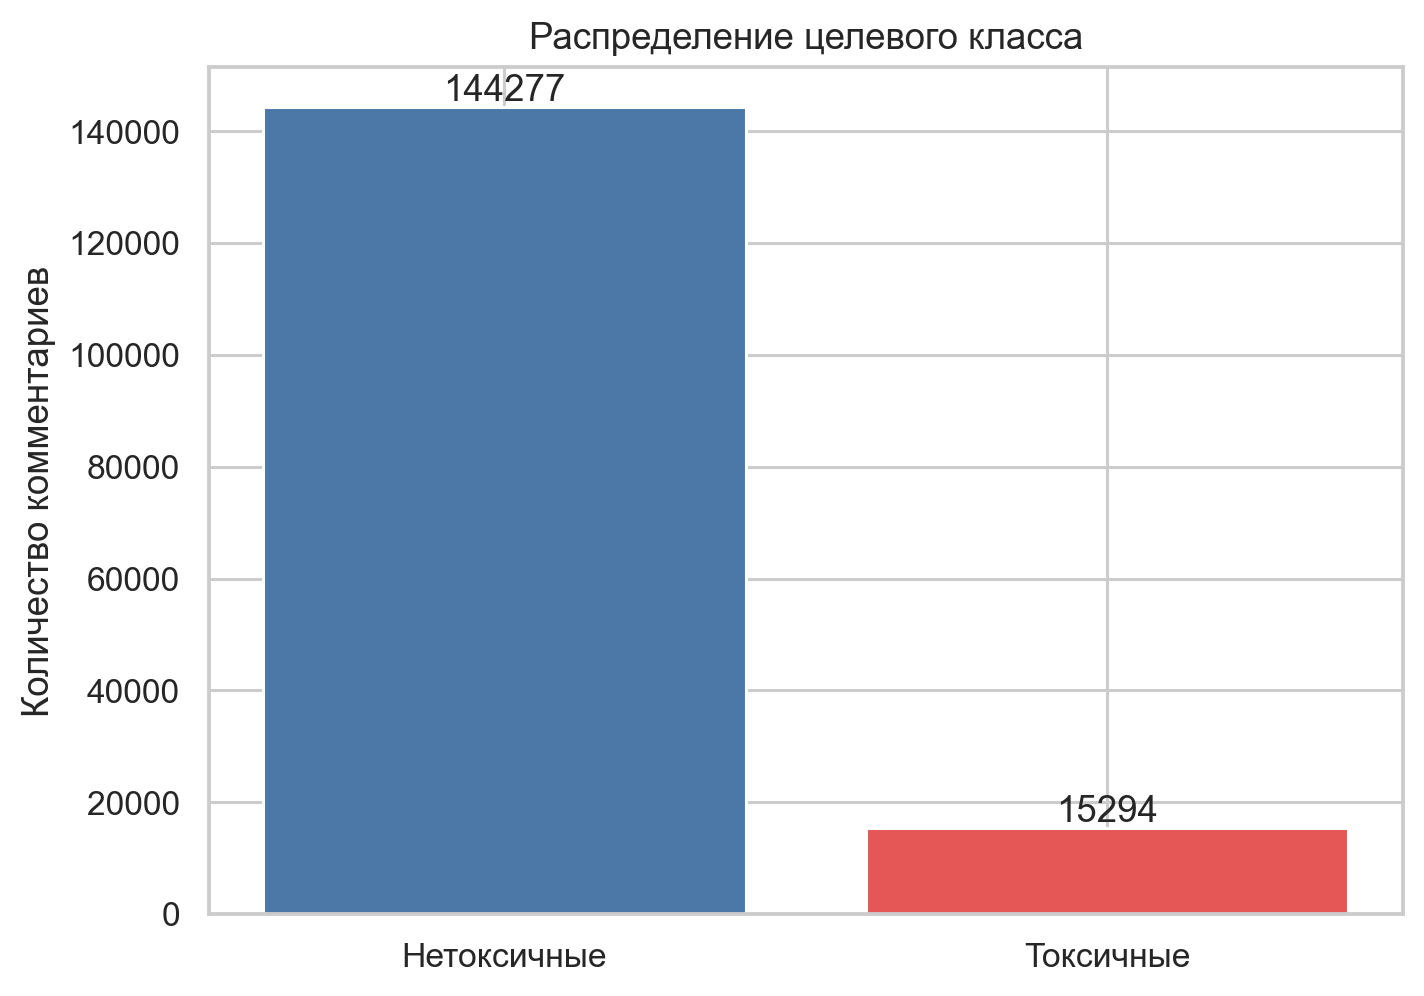

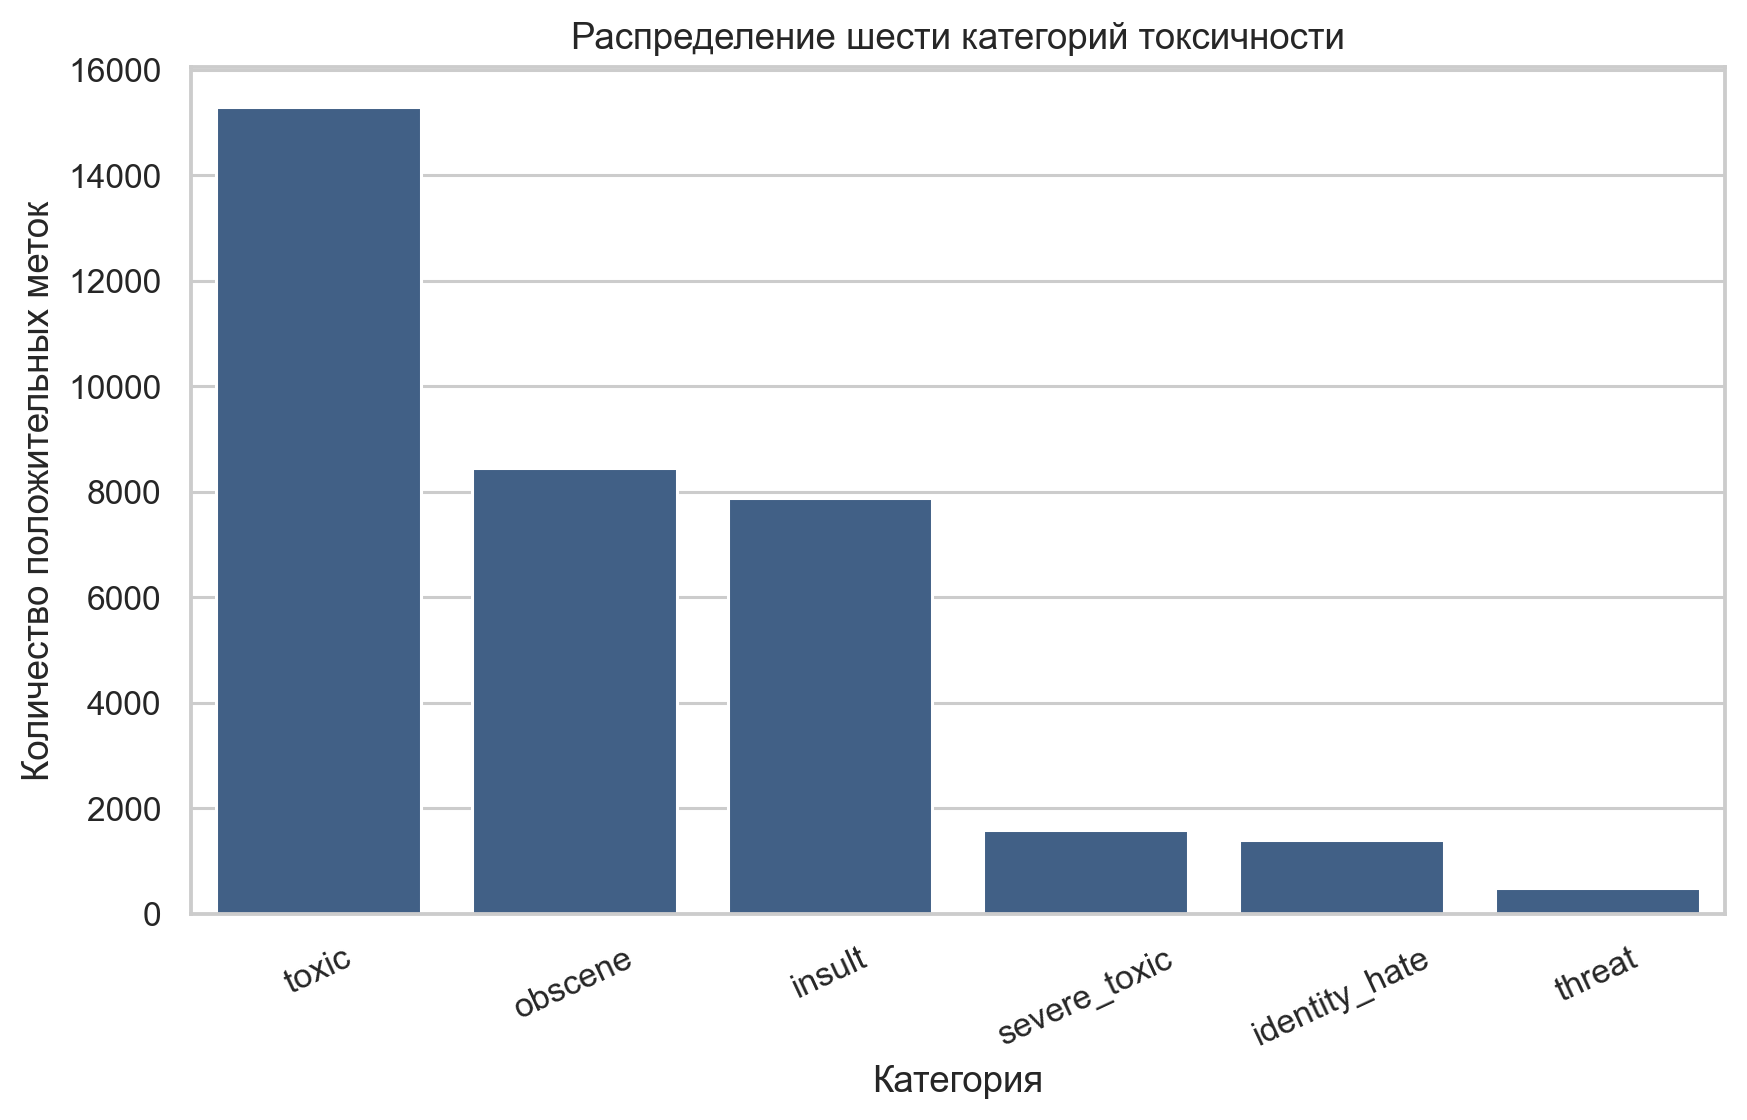

In [8]:
eda_summary = run_eda(frame, source_path, paths.figures_dir, paths.results_dir)
for filename in ("eda_target_distribution.png", "eda_all_labels.png"):
    display(Image(filename=str(paths.figures_dir / filename), width=760))

### 6.1. Длины комментариев

Помимо средних значений используются медиана и квантили, поскольку распределения длины имеют длинный правый хвост. Сравнение выполняется отдельно для токсичных и нетоксичных текстов.

,characters_mean,characters_median,characters_<lambda_0>,characters_<lambda_1>,characters_max,words_mean,words_median,words_<lambda_0>,words_<lambda_1>,words_max
toxic,,,,,,,,,,
0,404.55,216.0,916.0,3370.48,5000,68.97,38.0,156.0,563.00,1250
1,295.25,123.0,582.0,4370.42,5000,51.29,22.0,102.0,654.21,1411


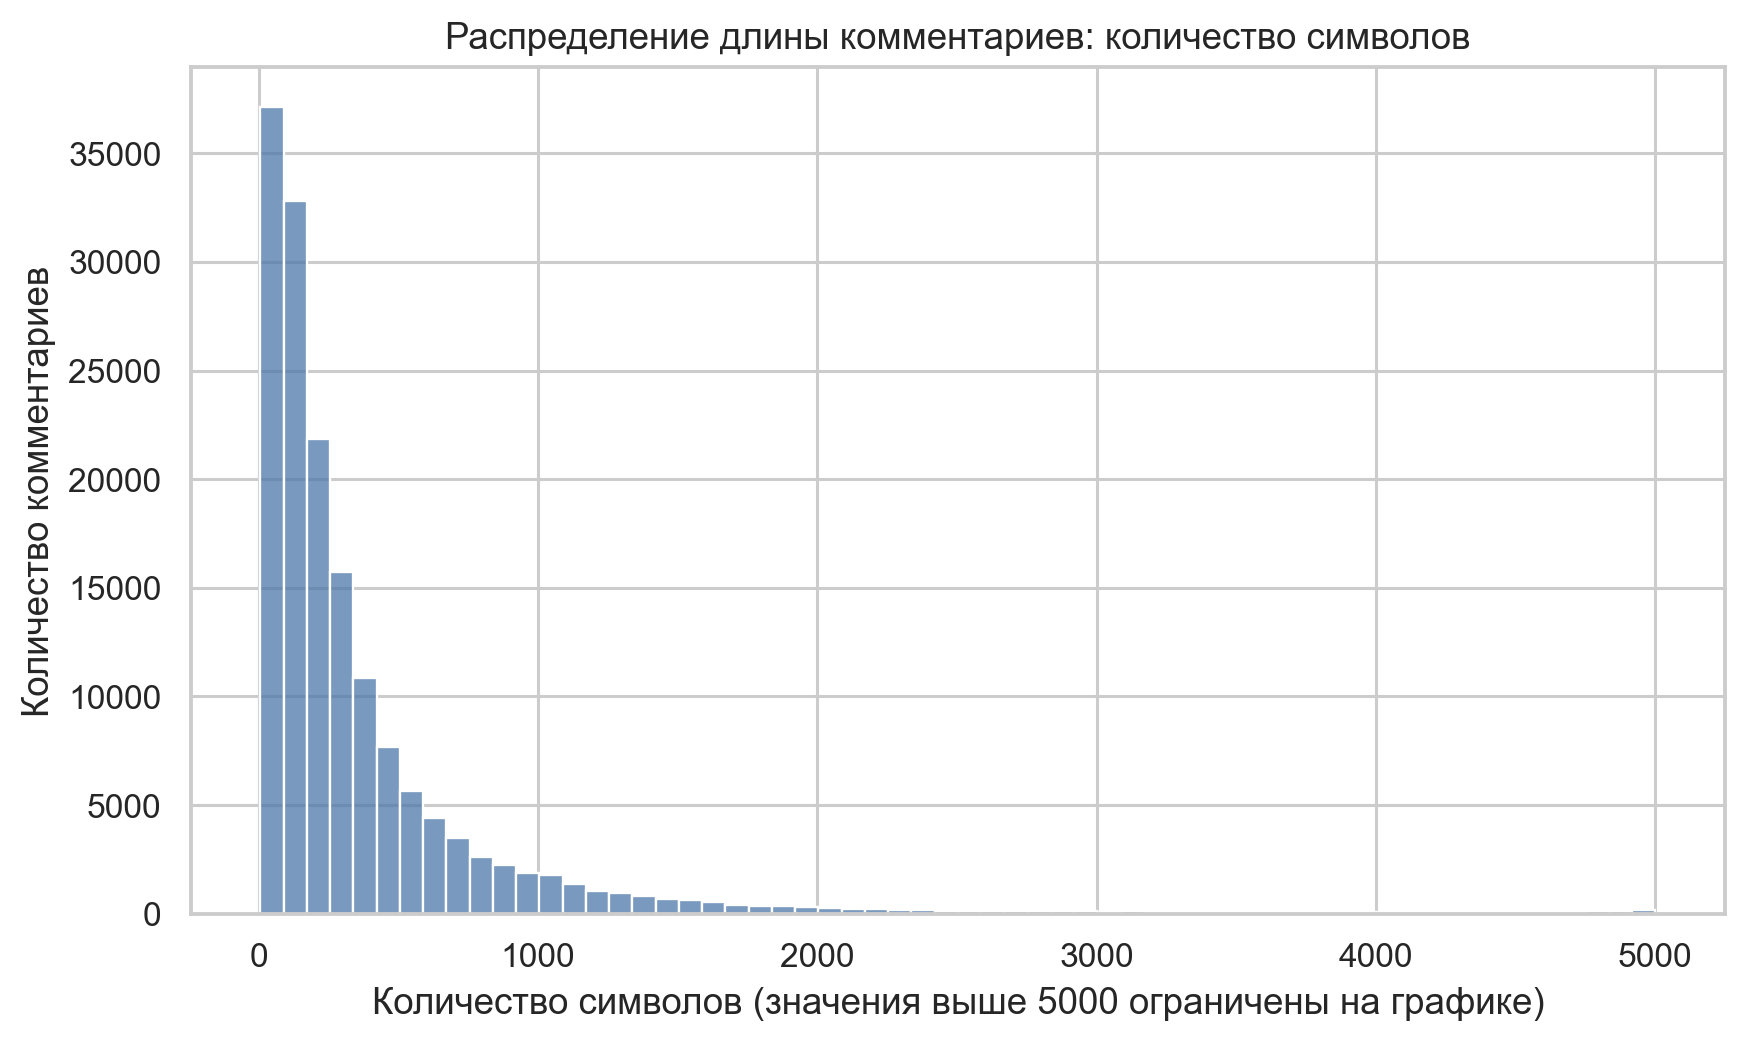

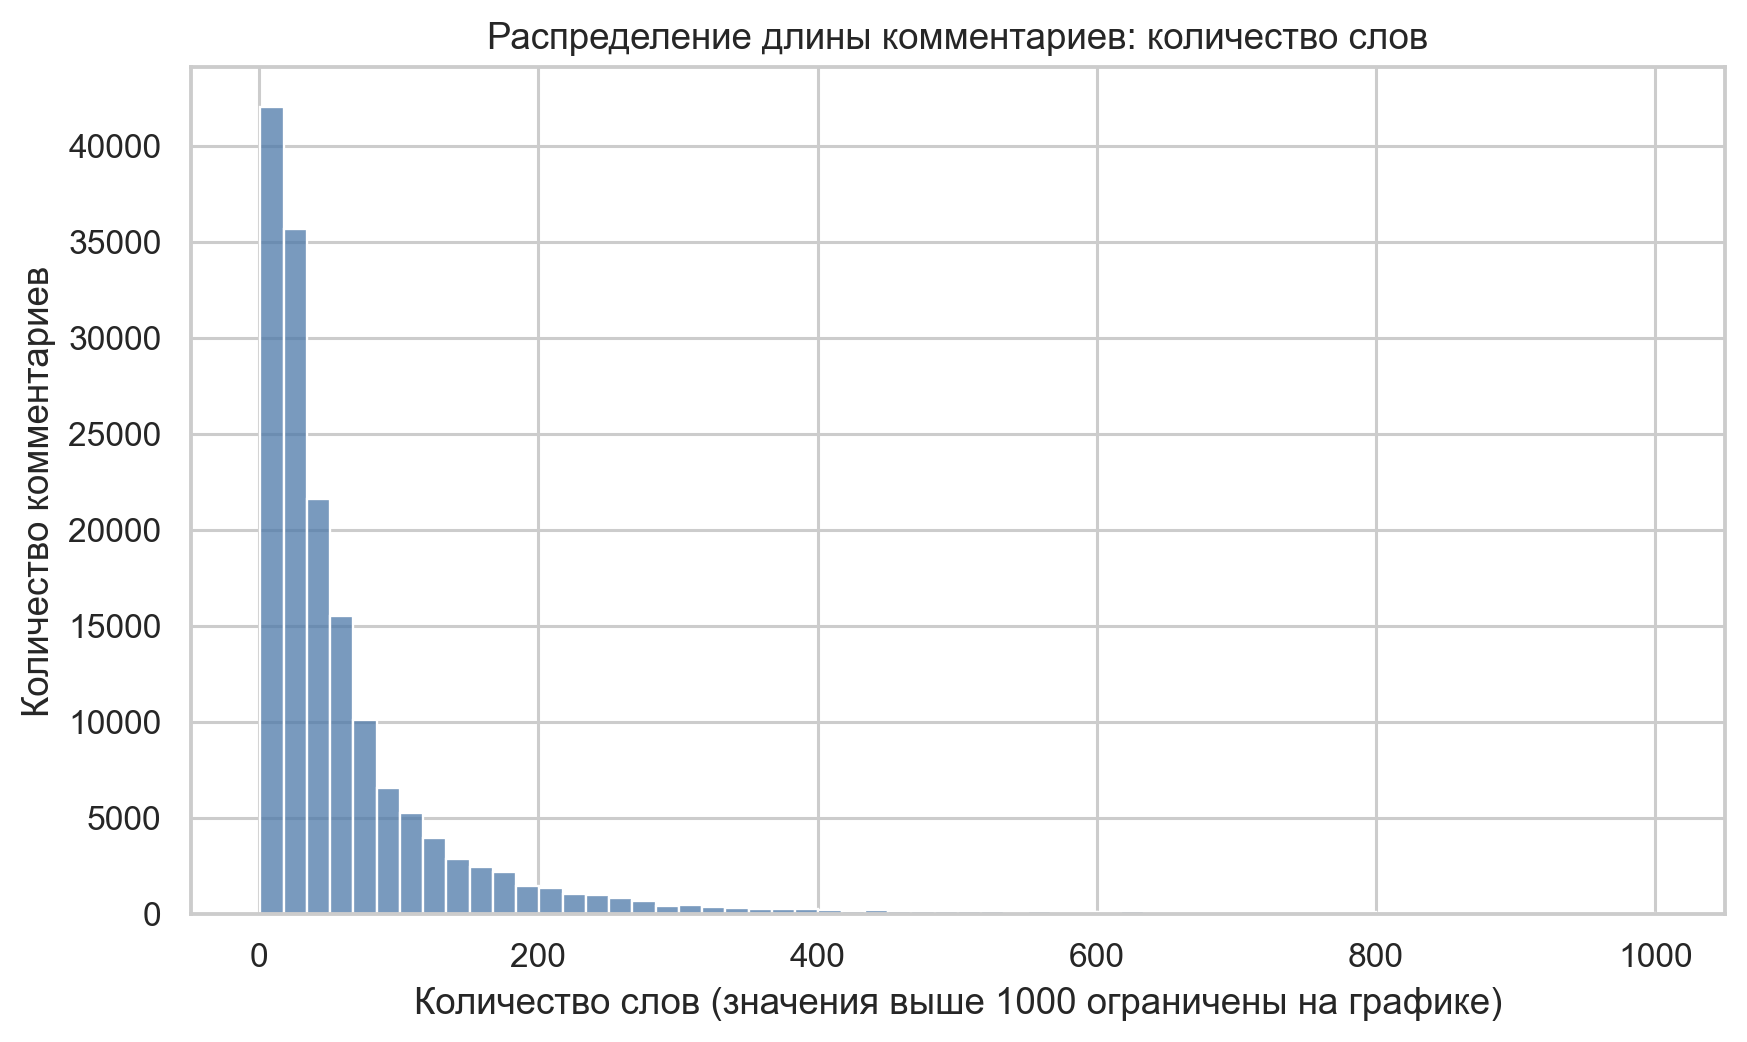

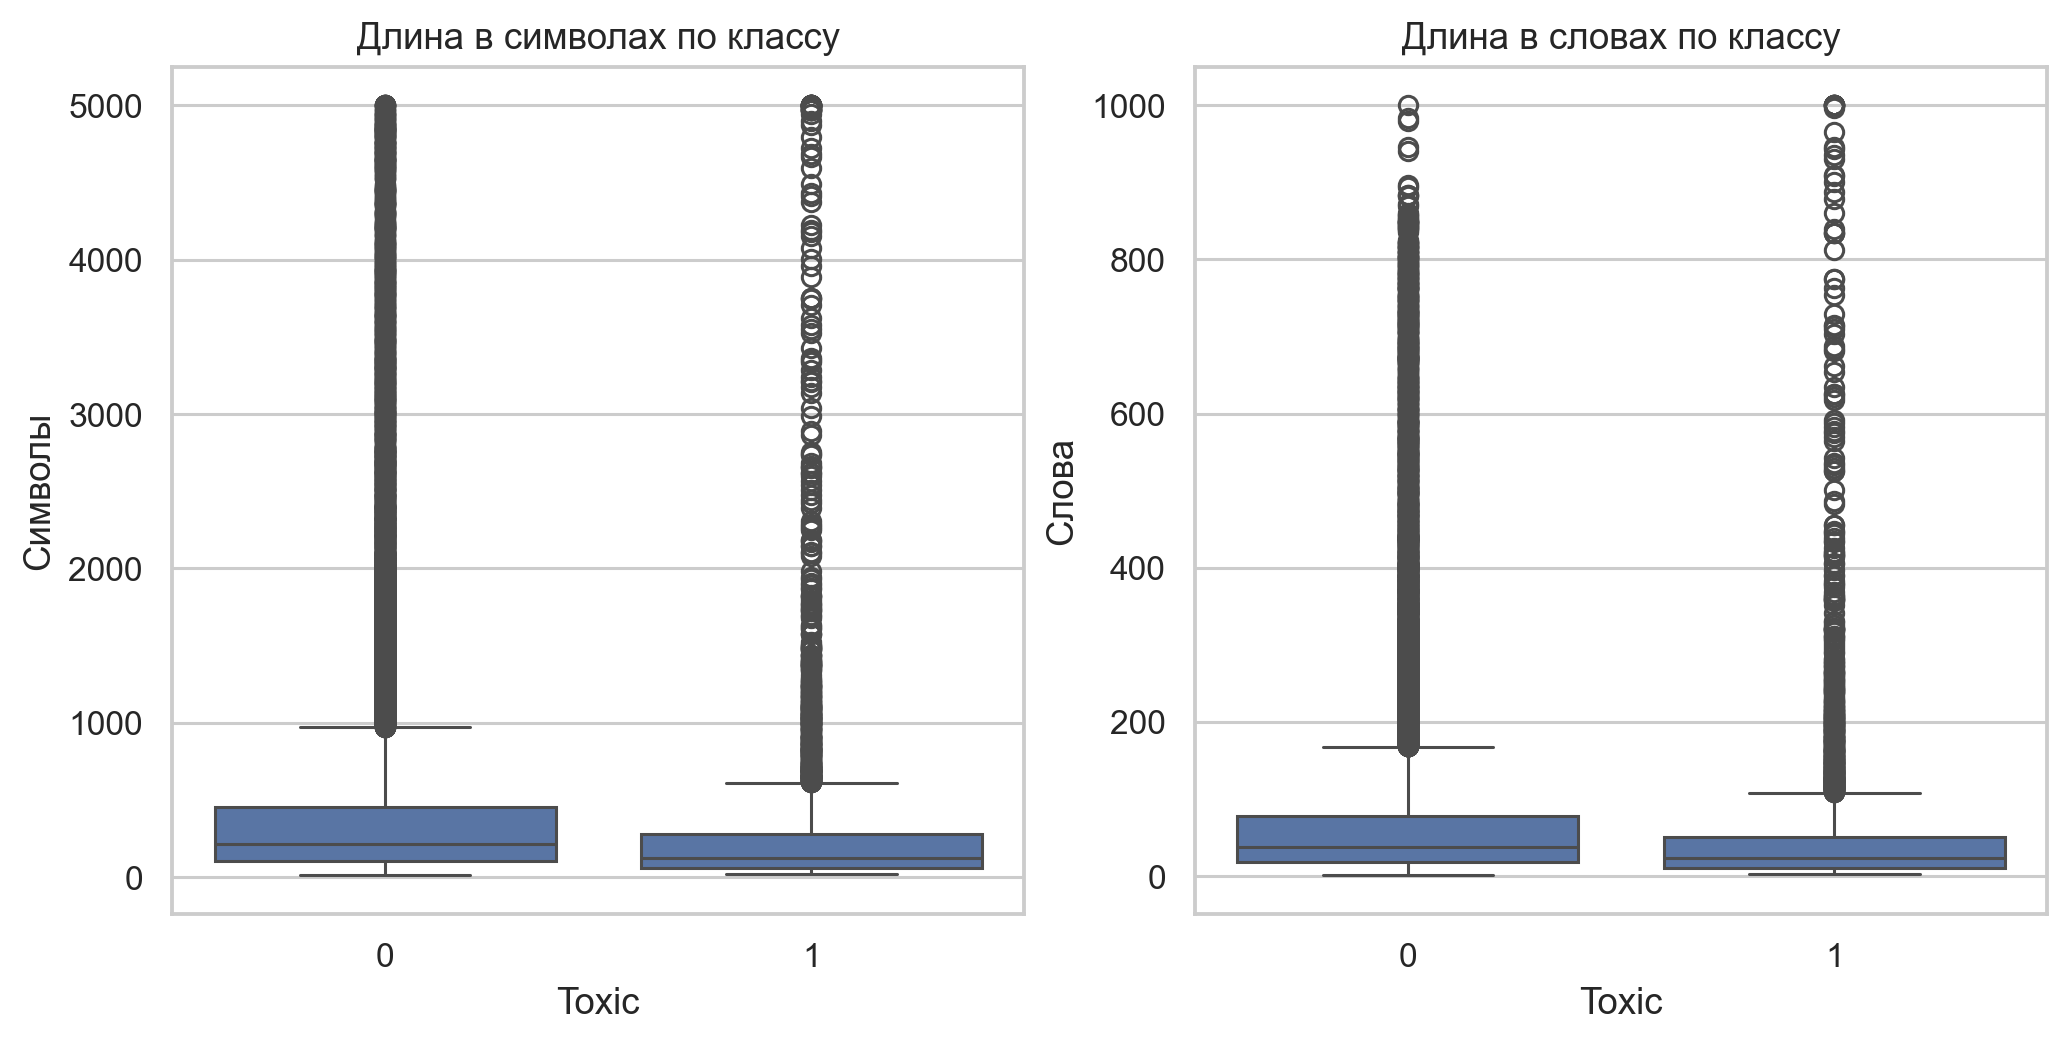

In [9]:
length_frame = pd.DataFrame(
    {
        "toxic": frame["toxic"],
        "characters": frame["comment_text"].astype(str).str.len(),
        "words": frame["comment_text"].astype(str).str.split().str.len(),
    }
)
length_statistics = length_frame.groupby("toxic")[["characters", "words"]].agg(
    ["mean", "median", lambda values: values.quantile(0.90), lambda values: values.quantile(0.99), "max"]
)
length_statistics.columns = [
    f"{variable}_{stat if isinstance(stat, str) else 'quantile'}"
    for variable, stat in length_statistics.columns
]
display(length_statistics.round(2))

for filename in (
    "eda_length_characters.png",
    "eda_length_words.png",
    "eda_length_by_class.png",
):
    display(Image(filename=str(paths.figures_dir / filename), width=760))

### 6.2. Частотный анализ и совместная встречаемость меток

Частотный анализ выполняется отдельно по классам после удаления только небольшого списка общеязыковых служебных слов. Матрица совместной встречаемости показывает не причинную связь, а количество комментариев, одновременно имеющих две метки.

class,non_toxic,toxic
word,,
about,11379,0
all,9100,3464
article,17229,0
ass,0,2941
but,15545,0
can,10366,0
don't,0,2497
fuck,0,9922
fucking,0,3289


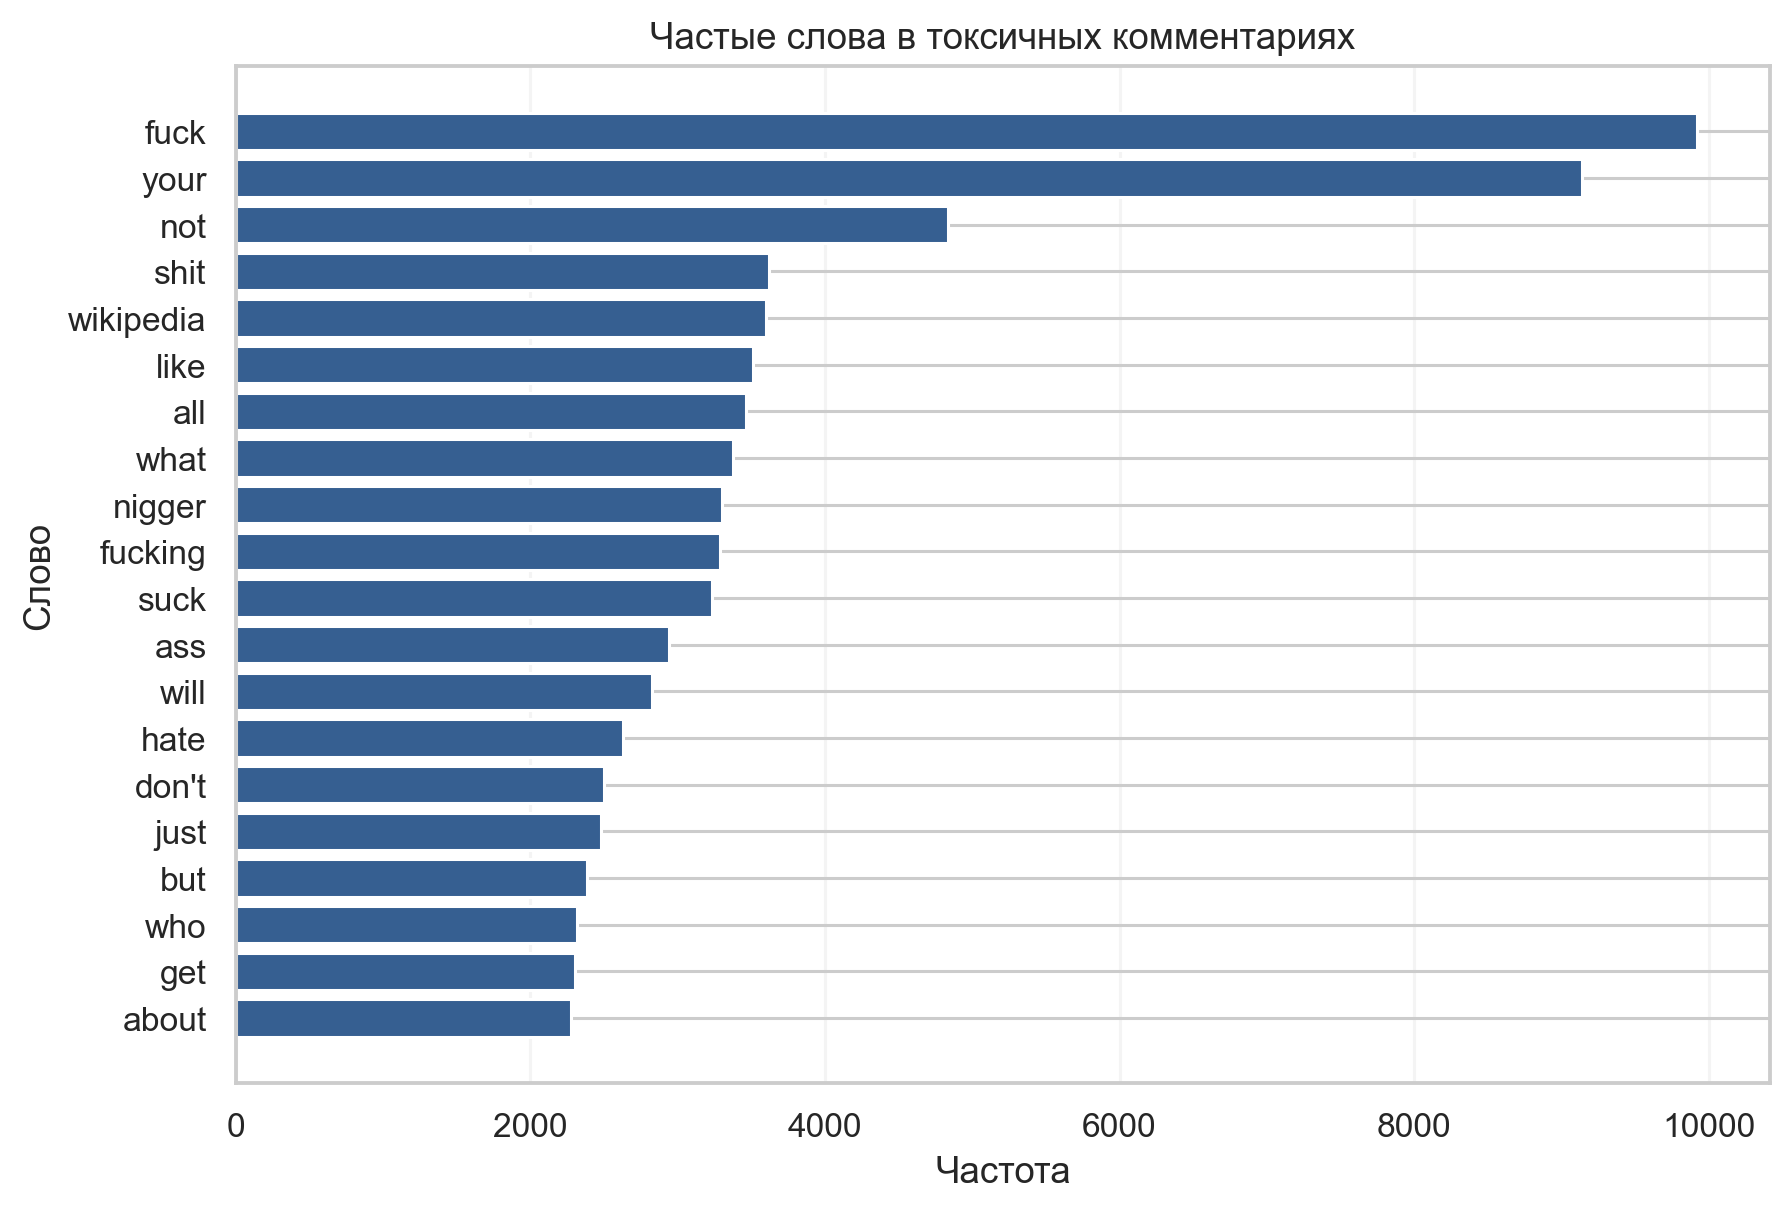

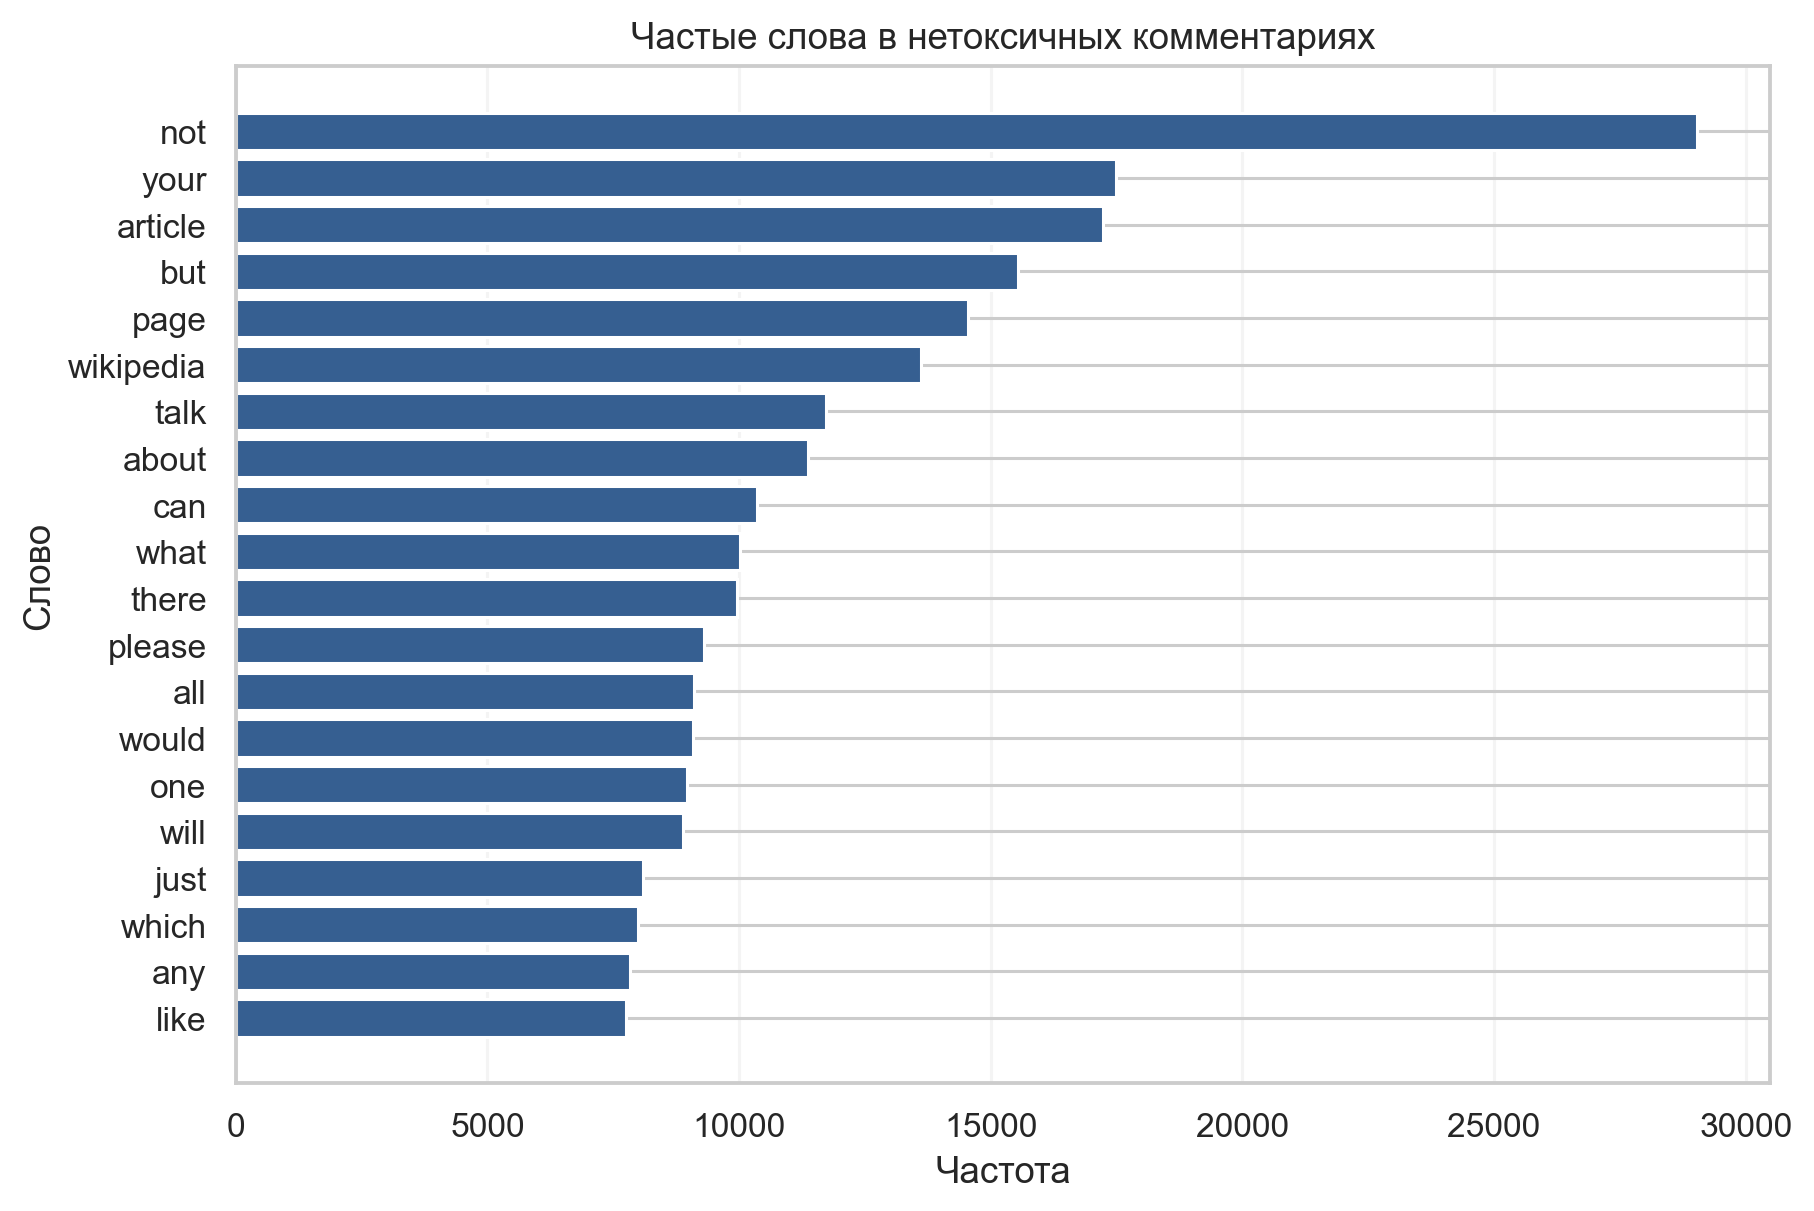

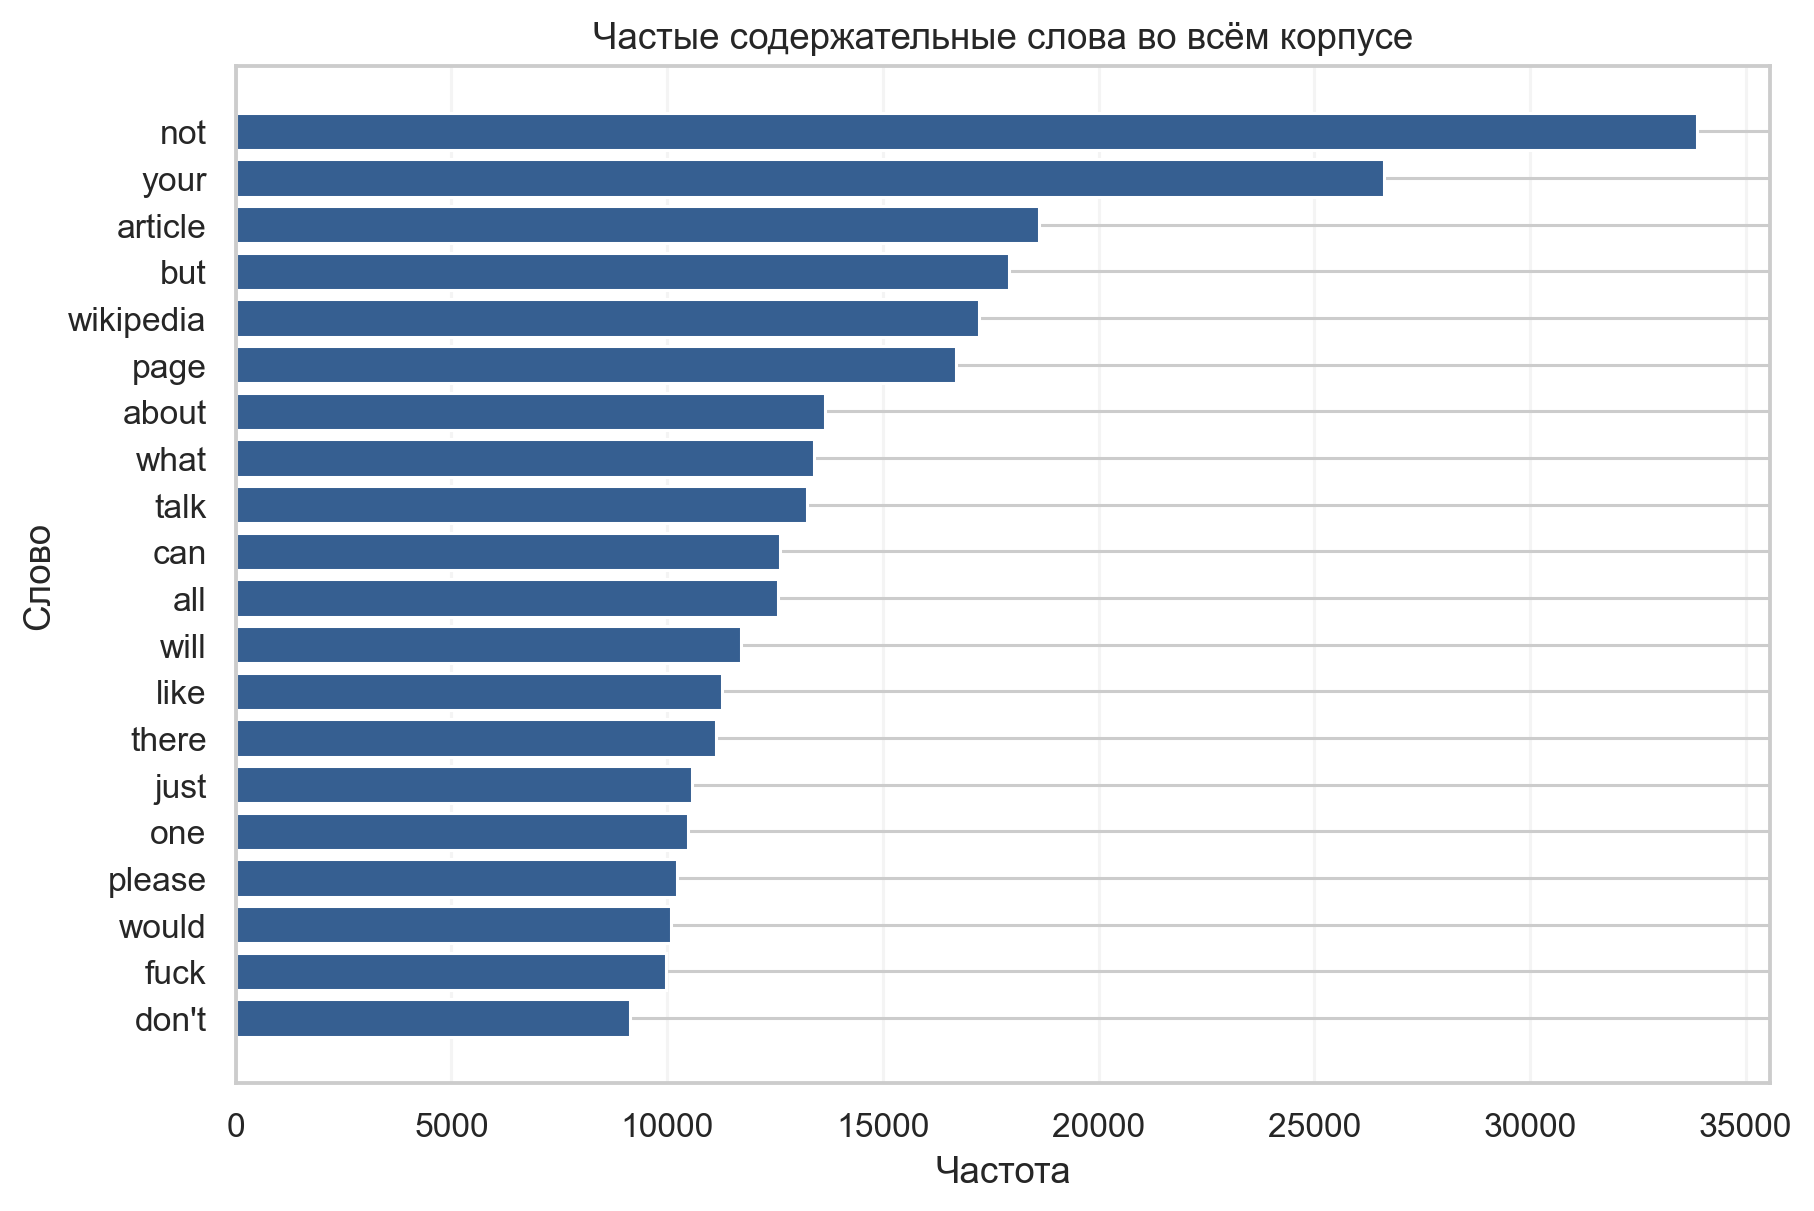

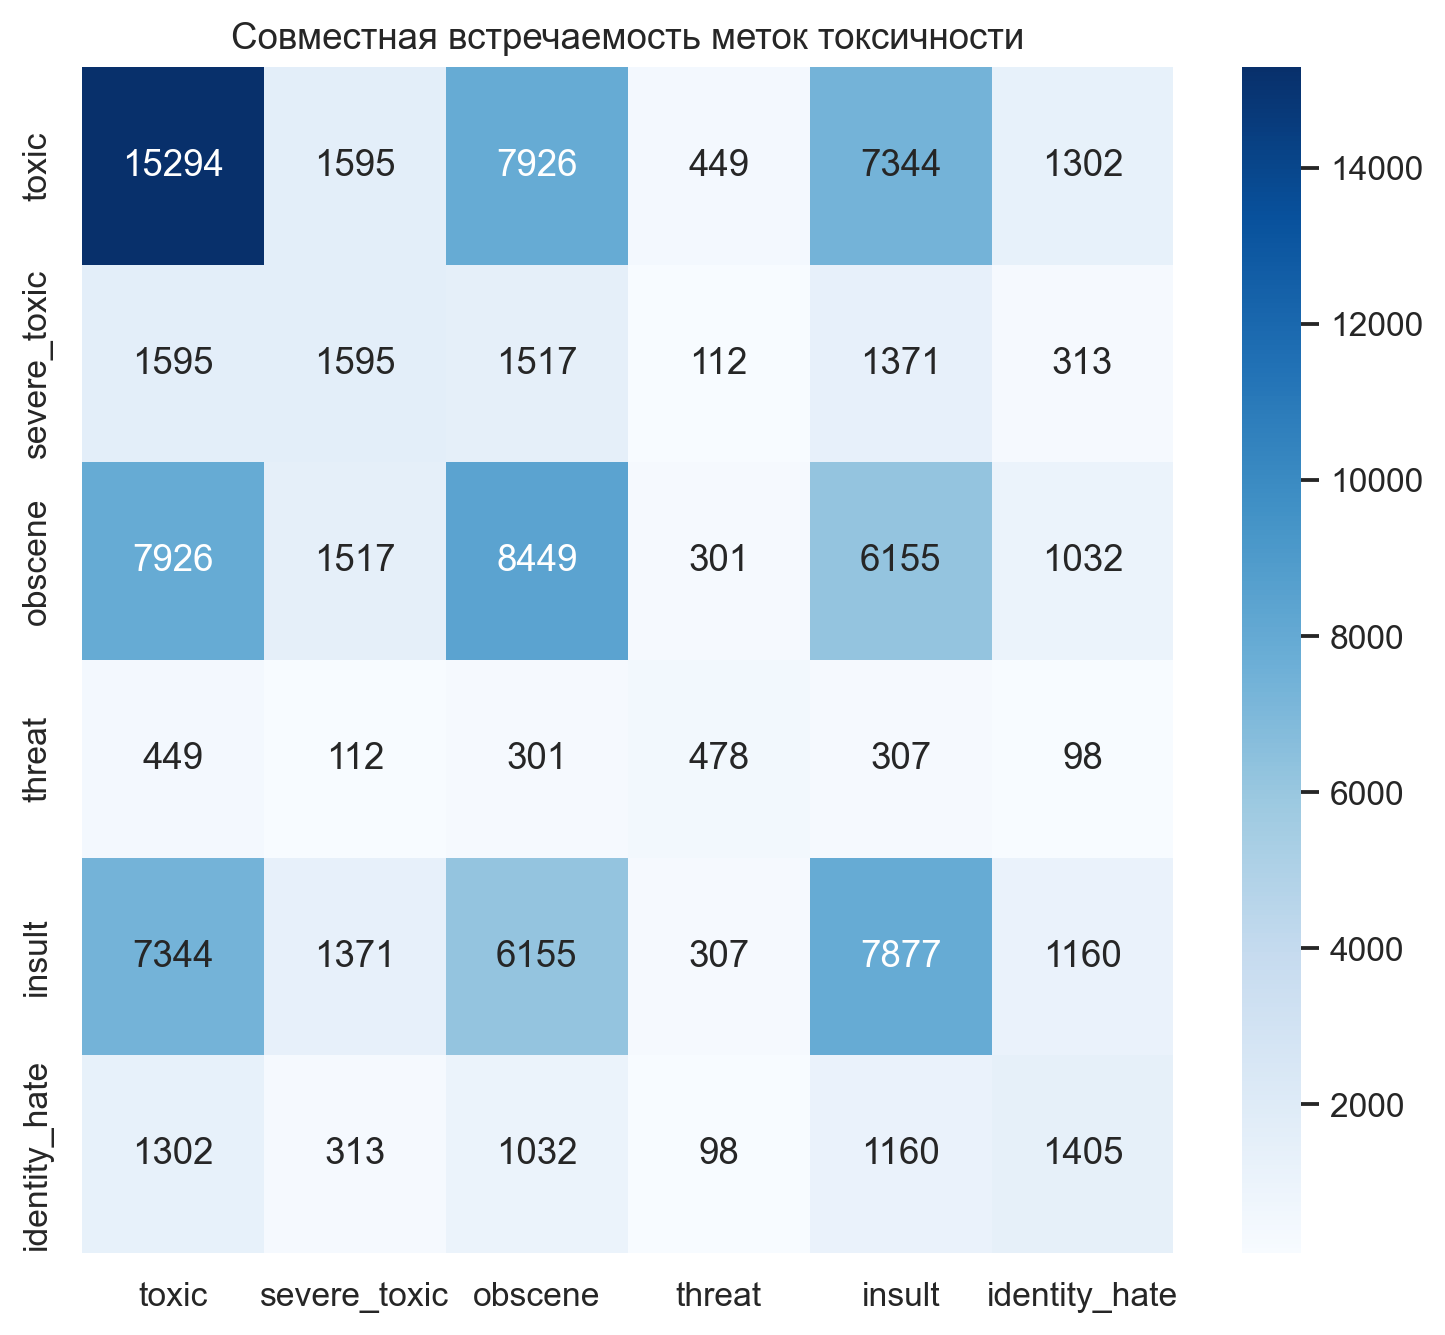

In [10]:
word_frequencies = pd.read_csv(paths.results_dir / "word_frequencies.csv")
top_words = (
    word_frequencies.sort_values(["class", "count"], ascending=[True, False])
    .groupby("class", group_keys=False)
    .head(15)
)
display(top_words.pivot(index="word", columns="class", values="count").fillna(0).astype(int))

for filename in (
    "eda_words_toxic.png",
    "eda_words_nontoxic.png",
    "eda_words_all.png",
    "eda_label_cooccurrence.png",
):
    display(Image(filename=str(paths.figures_dir / filename), width=760))

## 7. Дедупликация и единое разбиение 70/15/15

Повторяющиеся тексты удаляются **до** разбиения. Индексы сохраняются в `data/processed/split_manifest.csv`, поэтому все модели получают одну и ту же тестовую выборку. Стратификация выполняется по `toxic`, `random_state=42`.

In [11]:
clean_frame, removed_duplicate_texts = remove_duplicate_texts(frame)
splits = create_or_load_splits(clean_frame, paths.processed_dir, seed=seed)

split_summary = pd.DataFrame(
    [
        {
            "split": name,
            "rows": len(part),
            "share": len(part) / len(clean_frame),
            "toxic_count": int(part["toxic"].sum()),
            "toxic_share": part["toxic"].mean(),
        }
        for name, part in splits.items()
    ]
)
print("Удалено повторяющихся текстов:", removed_duplicate_texts)
split_summary_display = split_summary.copy()
for column in ("share", "toxic_share"):
    split_summary_display[column] = split_summary_display[column].map("{:.2%}".format)
display(split_summary_display)

Удалено повторяющихся текстов: 0


,split,rows,share,toxic_count,toxic_share
0,train,111699,70.00%,10706,9.58%
1,validation,23936,15.00%,2294,9.58%
2,test,23936,15.00%,2294,9.58%


### 7.1. Проверка отсутствия утечки

Контролируются пересечения как по `comment_text`, так и по `id`. Векторизаторы далее находятся внутри `Pipeline` и обучаются только на `train`; порог выбирается на `validation`; `test` используется один раз для итоговой оценки.

In [12]:
pair_rows = []
for left, right in (("train", "validation"), ("train", "test"), ("validation", "test")):
    text_overlap = len(set(splits[left]["comment_text"]) & set(splits[right]["comment_text"]))
    id_overlap = len(set(splits[left]["id"]) & set(splits[right]["id"]))
    pair_rows.append(
        {"часть_A": left, "часть_B": right, "общих_текстов": text_overlap, "общих_id": id_overlap}
    )

leakage_check = pd.DataFrame(pair_rows)
display(leakage_check)
assert (leakage_check[["общих_текстов", "общих_id"]].to_numpy() == 0).all()
assert sum(len(part) for part in splits.values()) == len(clean_frame)
print("Проверка пройдена: пересечений между частями нет.")

,часть_A,часть_B,общих_текстов,общих_id
0,train,validation,0,0
1,train,test,0,0
2,validation,test,0,0


Проверка пройдена: пересечений между частями нет.


## 8. Варианты предобработки текста

- **minimal** — нормализация пробельных символов с сохранением структуры;
- **standard** — lowercase, HTML, URL, пробелы и токенизация;
- **extended** — дополнительно stopwords и лемматизация WordNet с сохранением отрицаний.

Знаки `!` и `?`, отрицания и нецензурные слова не удаляются механически: они могут быть сильными признаками токсичности.

In [13]:
preprocessing_examples = [
    "<b>You are NOT right!!!</b> See https://example.org — this isn't helpful.",
    "I can't say this was a stupid idea; it was actually useful.",
    "What a f00l... nobody wants your opinion!!!",
]
preprocessing_demo = []
for source_text in preprocessing_examples:
    row = {"original": source_text}
    for variant in ("minimal", "standard", "extended"):
        row[variant] = get_preprocessor(variant)(source_text)
    preprocessing_demo.append(row)
display(pd.DataFrame(preprocessing_demo))

,original,minimal,standard,extended
0,<b>You are NOT right!!!</b> See https://exampl...,<b>You are NOT right!!!</b> See https://exampl...,you are not right ! ! ! see url — this isn't h...,not right ! ! ! see url helpful
1,I can't say this was a stupid idea; it was act...,I can't say this was a stupid idea; it was act...,i can't say this was a stupid idea ; it was ac...,say stupid idea actually useful
2,What a f00l... nobody wants your opinion!!!,What a f00l... nobody wants your opinion!!!,what a f 00 l . . . nobody wants your opinion ...,f l nobody want opinion ! ! !


## 9. Протокол экспериментов

Для каждой модели сохраняются Accuracy, Precision, Recall, F1, ROC-AUC, PR-AUC, матрица ошибок и время обучения. Из-за дисбаланса основными критериями считаются F1 и PR-AUC. Для `LinearSVC` ROC-AUC и PR-AUC вычисляются по `decision_function` и не интерпретируются как калиброванные вероятности.

In [14]:
experiment_protocol = pd.DataFrame(
    [
        ["BoW + MultinomialNB", "CountVectorizer", "minimal", "alpha=0.5"],
        ["TF-IDF + Logistic Regression", "TfidfVectorizer", "3 варианта", "C: 0.5, 1, 2, 4"],
        ["TF-IDF + Linear SVM", "TfidfVectorizer", "minimal", "C: 0.25, 0.5, 1, 2"],
        ["DistilBERT", "WordPiece tokenizer", "minimal", "опциональный fine-tuning"],
    ],
    columns=["подход", "признаки", "предобработка", "настройка"],
)
display(experiment_protocol)
print("Train / validation / test:", *(len(splits[name]) for name in ("train", "validation", "test")))

,подход,признаки,предобработка,настройка
0,BoW + MultinomialNB,CountVectorizer,minimal,alpha=0.5
1,TF-IDF + Logistic Regression,TfidfVectorizer,3 варианта,"C: 0.5, 1, 2, 4"
2,TF-IDF + Linear SVM,TfidfVectorizer,minimal,"C: 0.25, 0.5, 1, 2"
3,DistilBERT,WordPiece tokenizer,minimal,опциональный fine-tuning


Train / validation / test: 111699 23936 23936


## 10. Обучение классических моделей

В полном режиме выполняется 16 запусков: три базовых модели, абляция предобработки, варианты TF-IDF и значения `C`. Каждый запуск сохраняет обученный `Pipeline` и тестовые предсказания. Это наиболее длительная ячейка notebook.

In [15]:
from toxicity.classical import run_classical_experiments

classical_results = run_classical_experiments(
    splits,
    config,
    paths.results_dir,
    paths.models_dir,
    paths.predictions_dir,
    quick=QUICK_MODE,
)

metric_columns = [
    "model",
    "preprocessing",
    "fit_seconds",
    "validation_f1",
    "test_accuracy",
    "test_precision",
    "test_recall",
    "test_f1",
    "test_roc_auc",
    "test_pr_auc",
]
display(classical_results[metric_columns].sort_values("test_f1", ascending=False).round(4))

,model,preprocessing,fit_seconds,validation_f1,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_pr_auc
3,tfidf_logreg_preprocess_standard,standard,18.9821,0.7900,0.9606,0.8131,0.7642,0.7879,0.9729,0.8726
4,tfidf_logreg_preprocess_extended,extended,26.6944,0.7906,0.9598,0.8085,0.7602,0.7836,0.9722,0.8683
11,tfidf_variant_1,minimal,5.7387,0.7801,0.9590,0.8023,0.7589,0.7800,0.9719,0.8657
13,tfidf_variant_3,minimal,15.4707,0.7709,0.9566,0.7677,0.7838,0.7757,0.9699,0.8615
8,tfidf_svm_c_0.25,minimal,14.8877,0.7729,0.9569,0.7741,0.7768,0.7755,0.9698,0.8595
1,tfidf_logistic_regression,minimal,17.3133,0.7728,0.9571,0.7782,0.7724,0.7753,0.9698,0.8610
12,tfidf_variant_2,minimal,15.6518,0.7728,0.9571,0.7782,0.7724,0.7753,0.9698,0.8610
15,tfidf_variant_5,minimal,15.7152,0.7670,0.9563,0.7658,0.7838,0.7747,0.9688,0.8565
2,tfidf_linear_svm,minimal,17.6897,0.7713,0.9582,0.8063,0.7419,0.7728,0.9647,0.8542
9,tfidf_svm_c_0.5,minimal,15.4002,0.7743,0.9578,0.8021,0.7437,0.7718,0.9679,0.8587


## 11. Эксперимент 1 — сравнение алгоритмов

Для честного основного сравнения берутся заранее определённые базовые конфигурации. Улучшенные варианты предобработки показываются отдельно, чтобы настройка не маскировала различия между семействами алгоритмов.

In [16]:
primary_names = ["bow_multinomial_nb", "tfidf_logistic_regression", "tfidf_linear_svm"]
primary_results = classical_results[classical_results["model"].isin(primary_names)].copy()
display(primary_results[metric_columns].sort_values("test_f1", ascending=False).round(4))

best_primary = primary_results.loc[primary_results["test_f1"].idxmax()]
display(
    Markdown(
        f"**Лучший базовый классический подход:** `{best_primary['model']}`; "
        f"F1 = **{best_primary['test_f1']:.4f}**, PR-AUC = **{best_primary['test_pr_auc']:.4f}**."
    )
)

,model,preprocessing,fit_seconds,validation_f1,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_pr_auc
1,tfidf_logistic_regression,minimal,17.3133,0.7728,0.9571,0.7782,0.7724,0.7753,0.9698,0.8610
2,tfidf_linear_svm,minimal,17.6897,0.7713,0.9582,0.8063,0.7419,0.7728,0.9647,0.8542
0,bow_multinomial_nb,minimal,13.2196,0.6927,0.9449,0.7330,0.6691,0.6996,0.9188,0.6979


**Лучший базовый классический подход:** `tfidf_logistic_regression`; F1 = **0.7753**, PR-AUC = **0.8610**.

## 12. Эксперимент 2 — влияние предобработки

Сравнивается одна и та же Logistic Regression с одинаковым TF-IDF; изменяется только функция очистки. Поэтому различия можно связывать именно с предобработкой, а не с другим классификатором.

In [17]:
preprocessing_names = [
    "tfidf_logistic_regression",
    "tfidf_logreg_preprocess_standard",
    "tfidf_logreg_preprocess_extended",
]
preprocessing_results = classical_results[classical_results["model"].isin(preprocessing_names)][
    ["model", "preprocessing", "validation_f1", "test_precision", "test_recall", "test_f1", "test_pr_auc"]
].sort_values("test_f1", ascending=False)
display(preprocessing_results.round(4))

,model,preprocessing,validation_f1,test_precision,test_recall,test_f1,test_pr_auc
3,tfidf_logreg_preprocess_standard,standard,0.7900,0.8131,0.7642,0.7879,0.8726
4,tfidf_logreg_preprocess_extended,extended,0.7906,0.8085,0.7602,0.7836,0.8683
1,tfidf_logistic_regression,minimal,0.7728,0.7782,0.7724,0.7753,0.8610


## 13. Эксперимент 3 — параметры TF-IDF

Проверяются униграммы против униграмм+биграмм, `min_df`, размер словаря и сублинейный TF. Комбинаций немного, чтобы эксперимент оставался воспроизводимым на CPU.

In [18]:
tfidf_variant_results = classical_results[
    classical_results["model"].str.startswith("tfidf_variant_")
].copy()
tfidf_variant_results["parameters_readable"] = tfidf_variant_results["parameters"].map(
    lambda value: json.dumps(json.loads(value), ensure_ascii=False)
)
display(
    tfidf_variant_results[
        ["model", "parameters_readable", "validation_f1", "test_f1", "test_pr_auc", "fit_seconds"]
    ].sort_values("test_f1", ascending=False).round(4)
)

,model,parameters_readable,validation_f1,test_f1,test_pr_auc,fit_seconds
11,tfidf_variant_1,"{""C"": 4.0, ""max_features"": 120000, ""min_df"": 2...",0.7801,0.7800,0.8657,5.7387
13,tfidf_variant_3,"{""C"": 4.0, ""max_features"": 120000, ""min_df"": 5...",0.7709,0.7757,0.8615,15.4707
12,tfidf_variant_2,"{""C"": 4.0, ""max_features"": 120000, ""min_df"": 2...",0.7728,0.7753,0.8610,15.6518
15,tfidf_variant_5,"{""C"": 4.0, ""max_features"": 120000, ""min_df"": 2...",0.7670,0.7747,0.8565,15.7152
14,tfidf_variant_4,"{""C"": 4.0, ""max_features"": 60000, ""min_df"": 2,...",0.7734,0.7701,0.8555,17.3502


## 14. Эксперимент 4 — параметр регуляризации `C`

Малое `C` усиливает регуляризацию, большое — позволяет модели точнее подгоняться под обучающую выборку. Выбор лучшей настройки должен опираться на validation, а не на test.

In [19]:
c_results = classical_results[
    classical_results["model"].str.contains(r"tfidf_(logreg|svm)_c_", regex=True)
].copy()
c_results["C"] = c_results["parameters"].map(lambda value: json.loads(value)["C"])
c_results["classifier"] = np.where(c_results["model"].str.contains("logreg"), "Logistic Regression", "Linear SVM")
display(
    c_results[
        ["classifier", "C", "validation_f1", "test_precision", "test_recall", "test_f1", "test_pr_auc"]
    ].sort_values(["classifier", "C"]).round(4)
)

/var/folders/hg/n2pq71497lxdz_6rlbks6jhc0000gp/T/ipykernel_90903/1129727133.py:2: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  classical_results["model"].str.contains(r"tfidf_(logreg|svm)_c_", regex=True)


,classifier,C,validation_f1,test_precision,test_recall,test_f1,test_pr_auc
8,Linear SVM,0.25,0.7729,0.7741,0.7768,0.7755,0.8595
9,Linear SVM,0.50,0.7743,0.8021,0.7437,0.7718,0.8587
10,Linear SVM,2.00,0.7658,0.7935,0.7419,0.7668,0.8474
5,Logistic Regression,0.50,0.7374,0.7343,0.7685,0.7510,0.8350
6,Logistic Regression,1.00,0.7507,0.7525,0.7768,0.7645,0.8491
7,Logistic Regression,2.00,0.7664,0.7601,0.7816,0.7707,0.8572


## 15. Эксперимент 5 — влияние порога решения

Для лучшей Logistic Regression повторно вычисляются validation-оценки. Порог изменяется от 0.05 до 0.95, а Precision, Recall и F1 строятся только по validation. Test не используется для выбора порога.

,threshold,precision,recall,f1
0,0.05,0.2462,0.9830,0.3938
1,0.10,0.3518,0.9616,0.5151
2,0.15,0.4343,0.9455,0.5952
3,0.20,0.4948,0.9303,0.6460
4,0.25,0.5483,0.9137,0.6853
5,0.30,0.5936,0.9024,0.7161
6,0.35,0.6243,0.8875,0.7330
7,0.40,0.6585,0.8701,0.7497
8,0.45,0.6894,0.8553,0.7634
9,0.50,0.7142,0.8409,0.7724


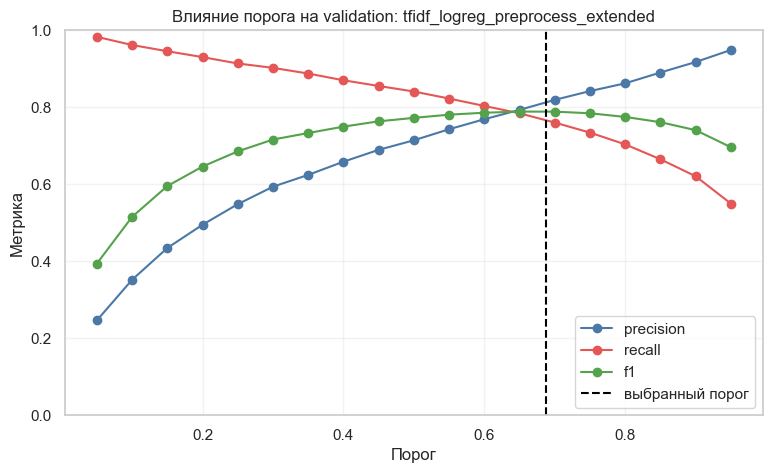

Порог, выбранный по validation: 0.6878


In [20]:
import joblib
from sklearn.metrics import f1_score, precision_score, recall_score

best_lr_row = classical_results[
    classical_results["model"].str.contains("logreg")
].sort_values("validation_f1", ascending=False).iloc[0]
best_lr_name = best_lr_row["model"]
best_lr_pipeline = joblib.load(paths.models_dir / f"{best_lr_name}.joblib")
validation_scores = best_lr_pipeline.predict_proba(splits["validation"]["comment_text"])[:, 1]
y_validation = splits["validation"]["toxic"].to_numpy()

threshold_rows = []
for threshold in np.linspace(0.05, 0.95, 19):
    prediction = (validation_scores >= threshold).astype(int)
    threshold_rows.append(
        {
            "threshold": threshold,
            "precision": precision_score(y_validation, prediction, zero_division=0),
            "recall": recall_score(y_validation, prediction, zero_division=0),
            "f1": f1_score(y_validation, prediction, zero_division=0),
        }
    )
threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results.round(4))

fig, ax = plt.subplots(figsize=(9, 5))
for metric, color in (("precision", "#4c78a8"), ("recall", "#e45756"), ("f1", "#54a24b")):
    ax.plot(threshold_results["threshold"], threshold_results[metric], marker="o", label=metric, color=color)
ax.axvline(best_lr_row["validation_threshold"], color="black", linestyle="--", label="выбранный порог")
ax.set(title=f"Влияние порога на validation: {best_lr_name}", xlabel="Порог", ylabel="Метрика", ylim=(0, 1))
ax.grid(alpha=0.25)
ax.legend()
threshold_figure = paths.figures_dir / "results_threshold_tradeoff.png"
fig.savefig(threshold_figure, dpi=220, bbox_inches="tight", facecolor="white")
plt.show()

print("Порог, выбранный по validation:", round(float(best_lr_row["validation_threshold"]), 4))

## 16. Итоговые графики качества

Ниже представлены сравнение F1, Precision/Recall, ROC- и Precision–Recall-кривые, матрицы ошибок, а также влияние `C` и предобработки. PR-кривая особенно информативна при редком положительном классе.

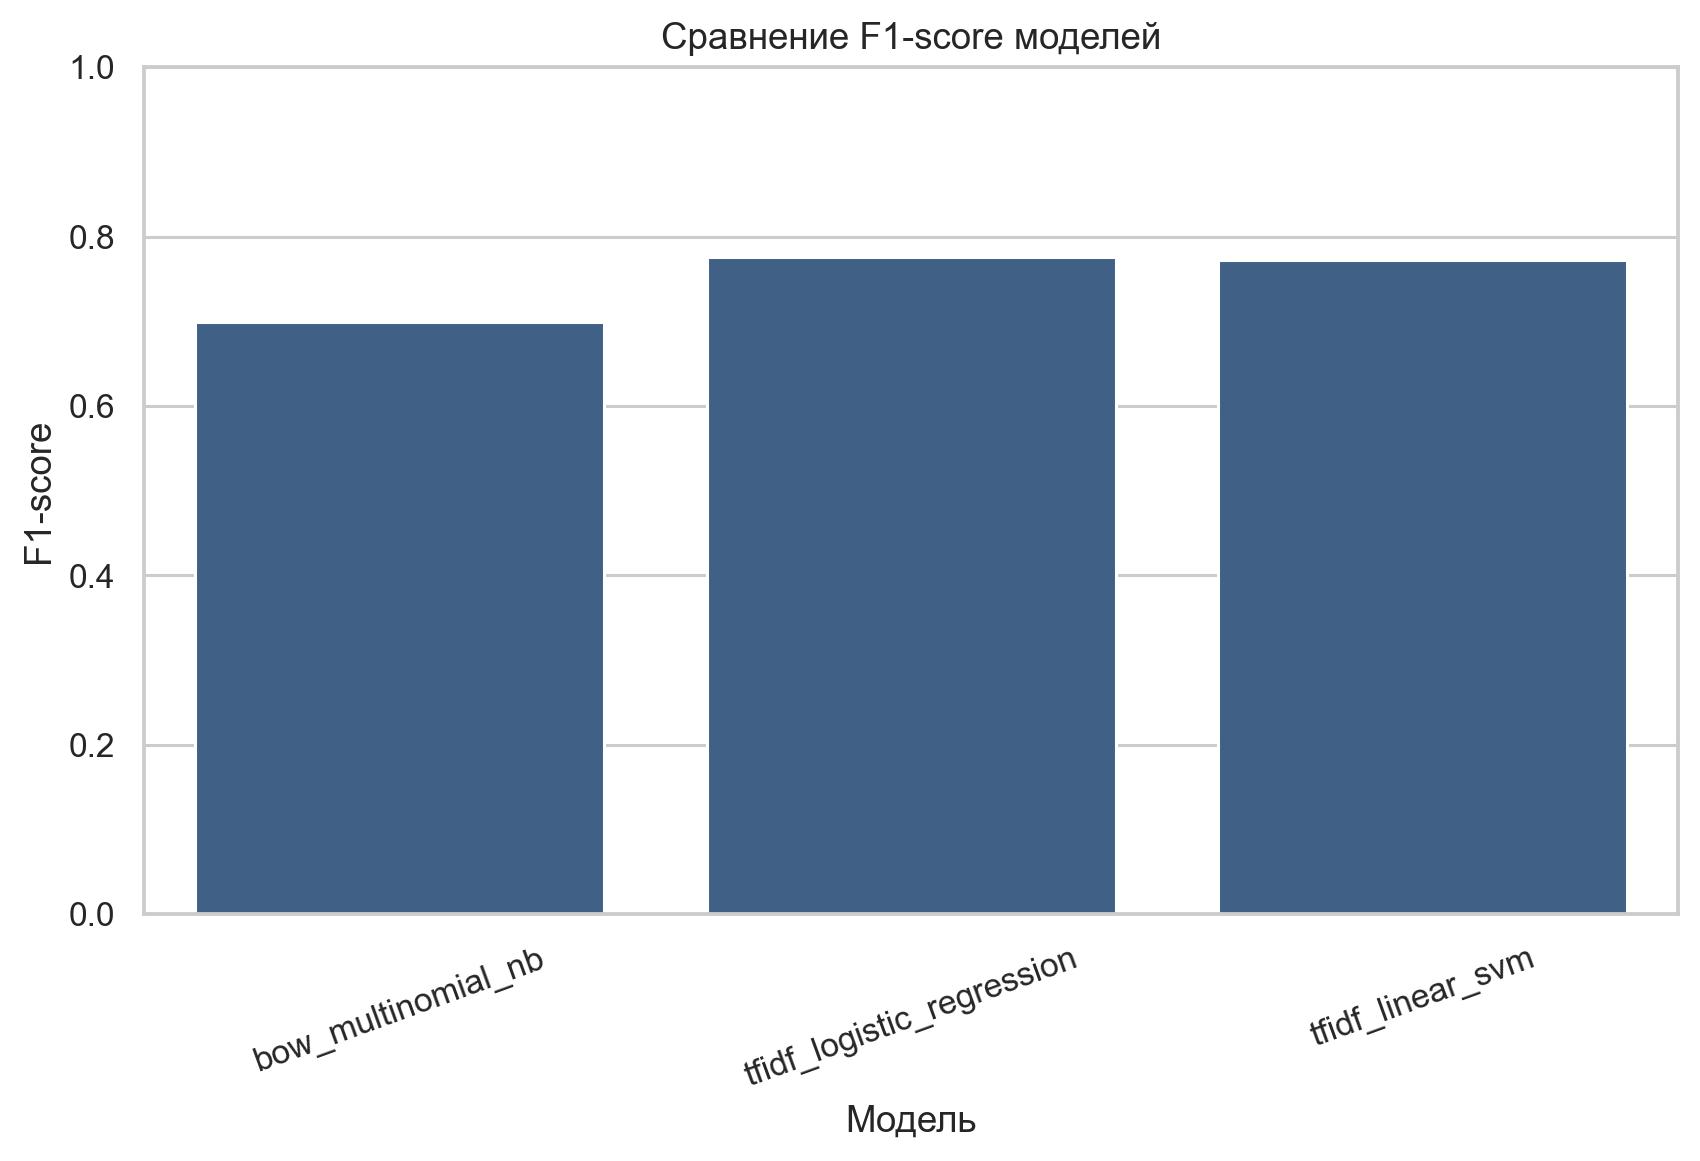

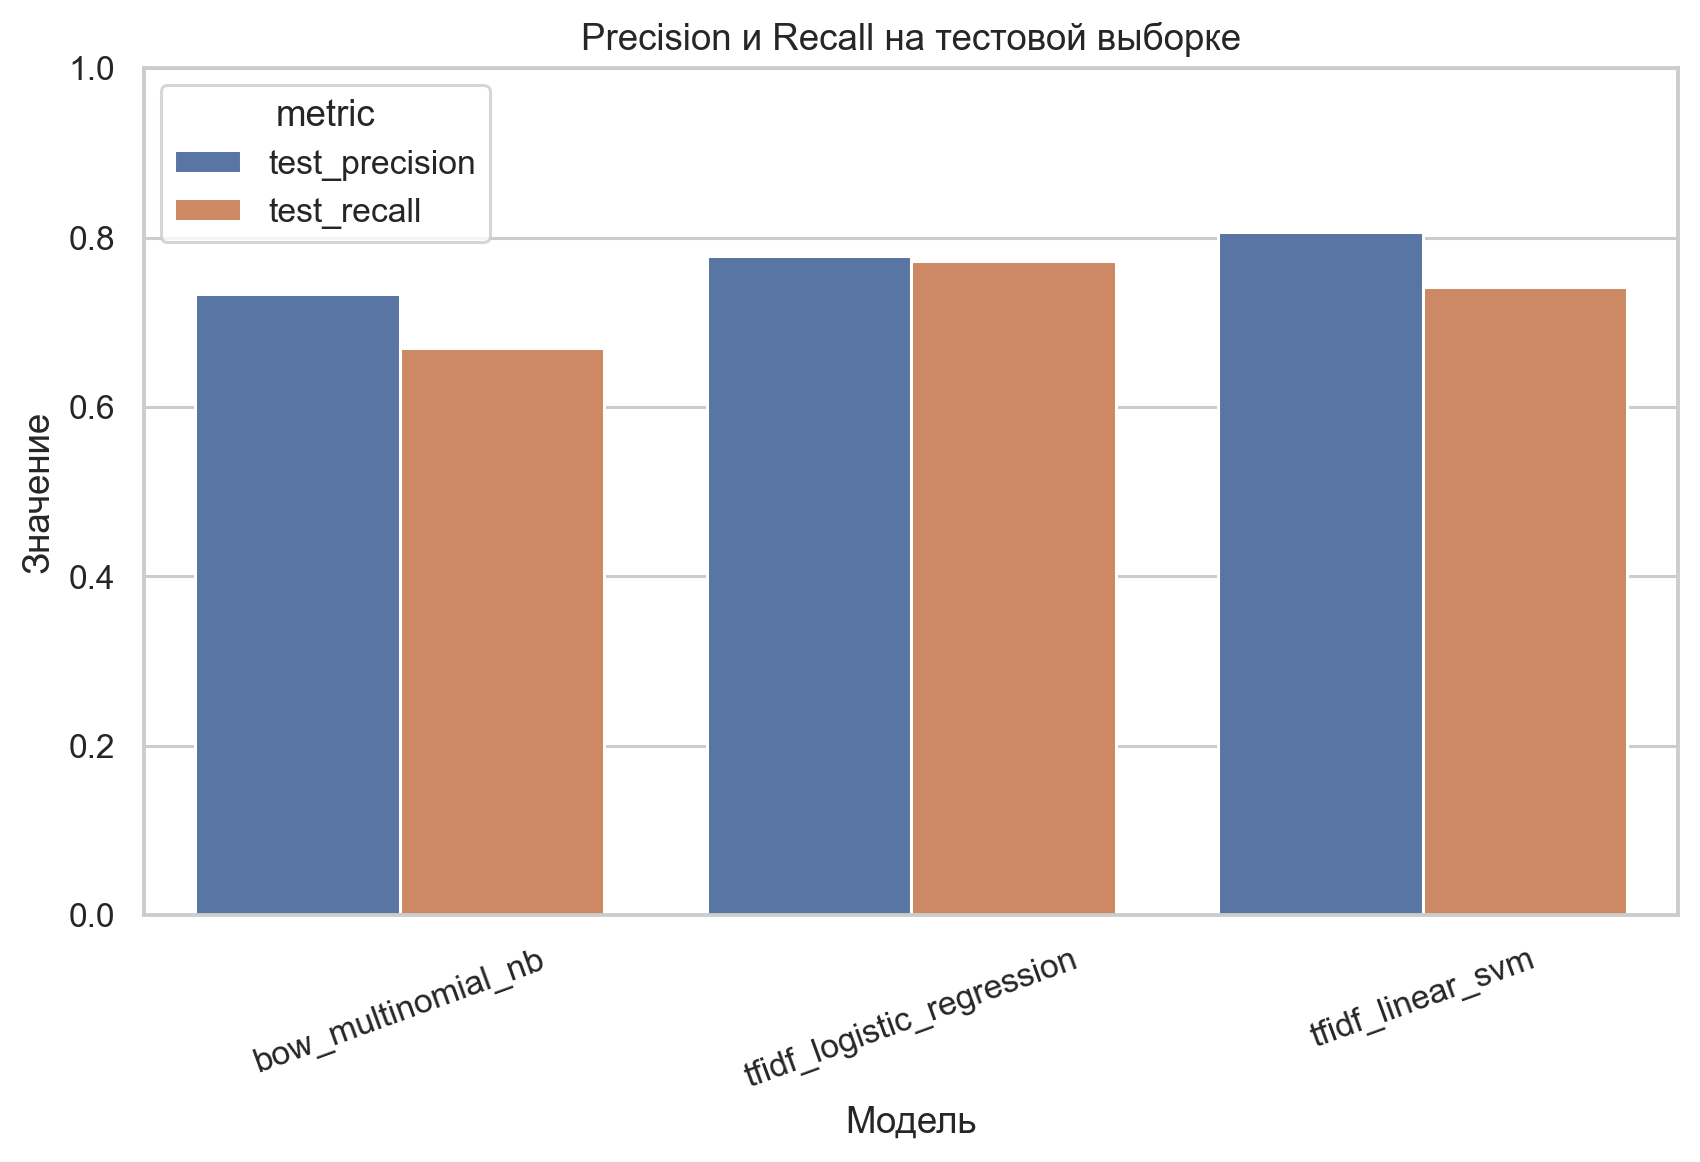

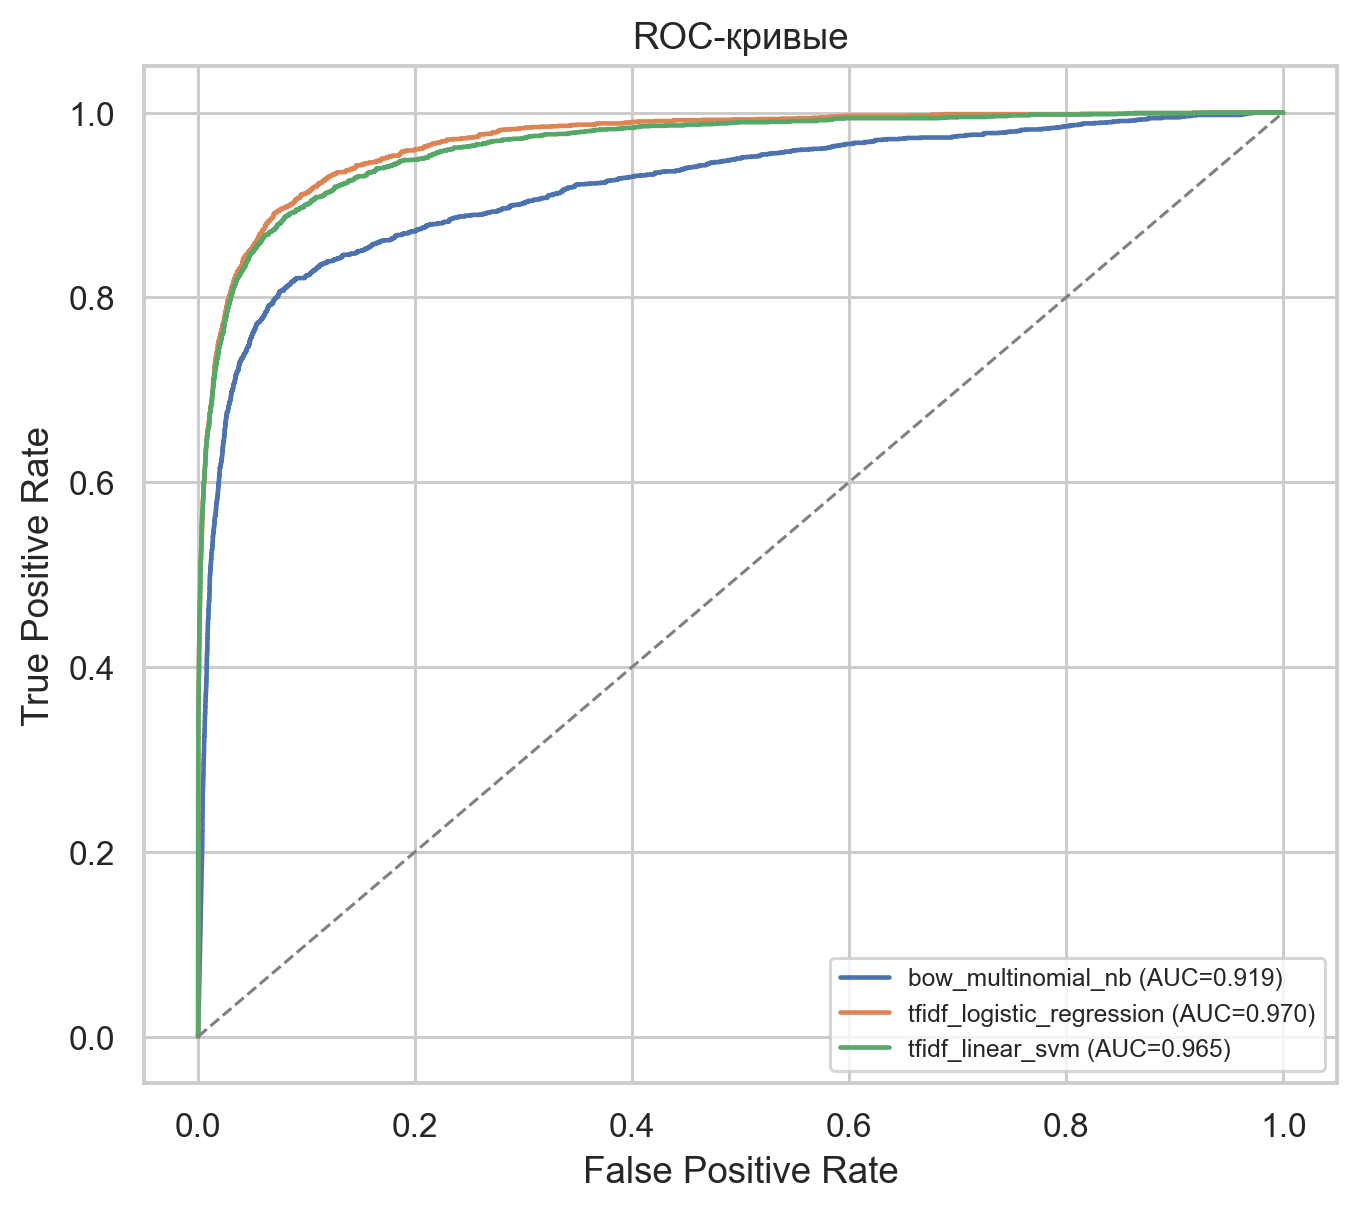

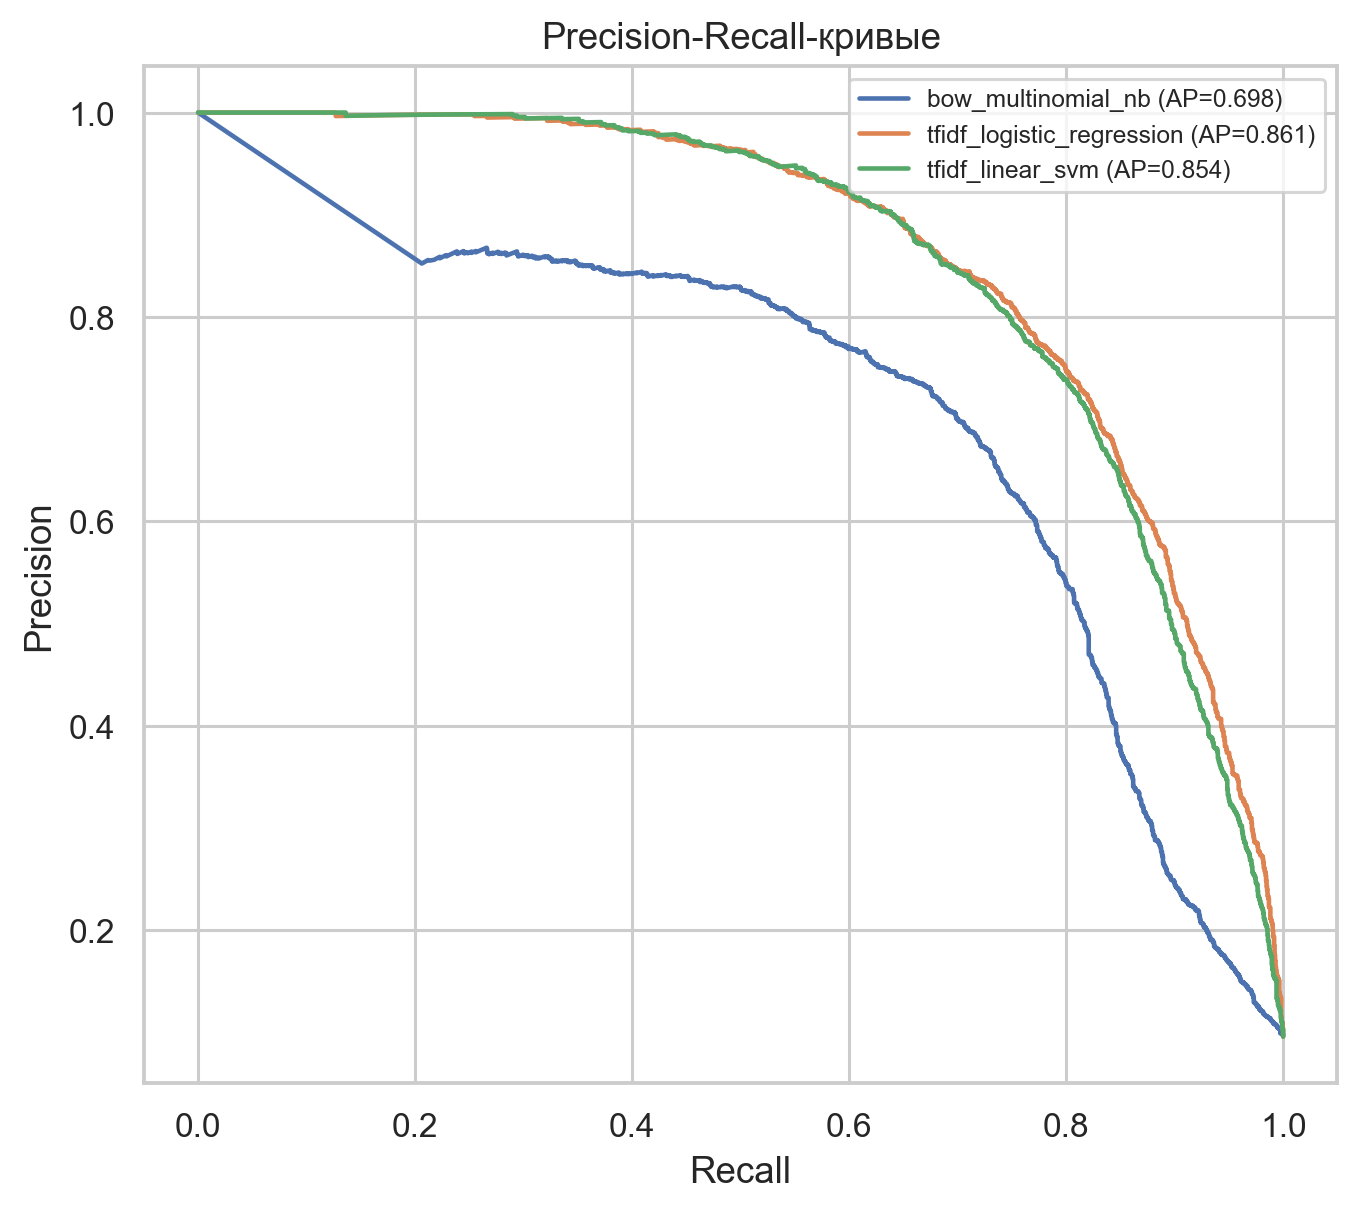

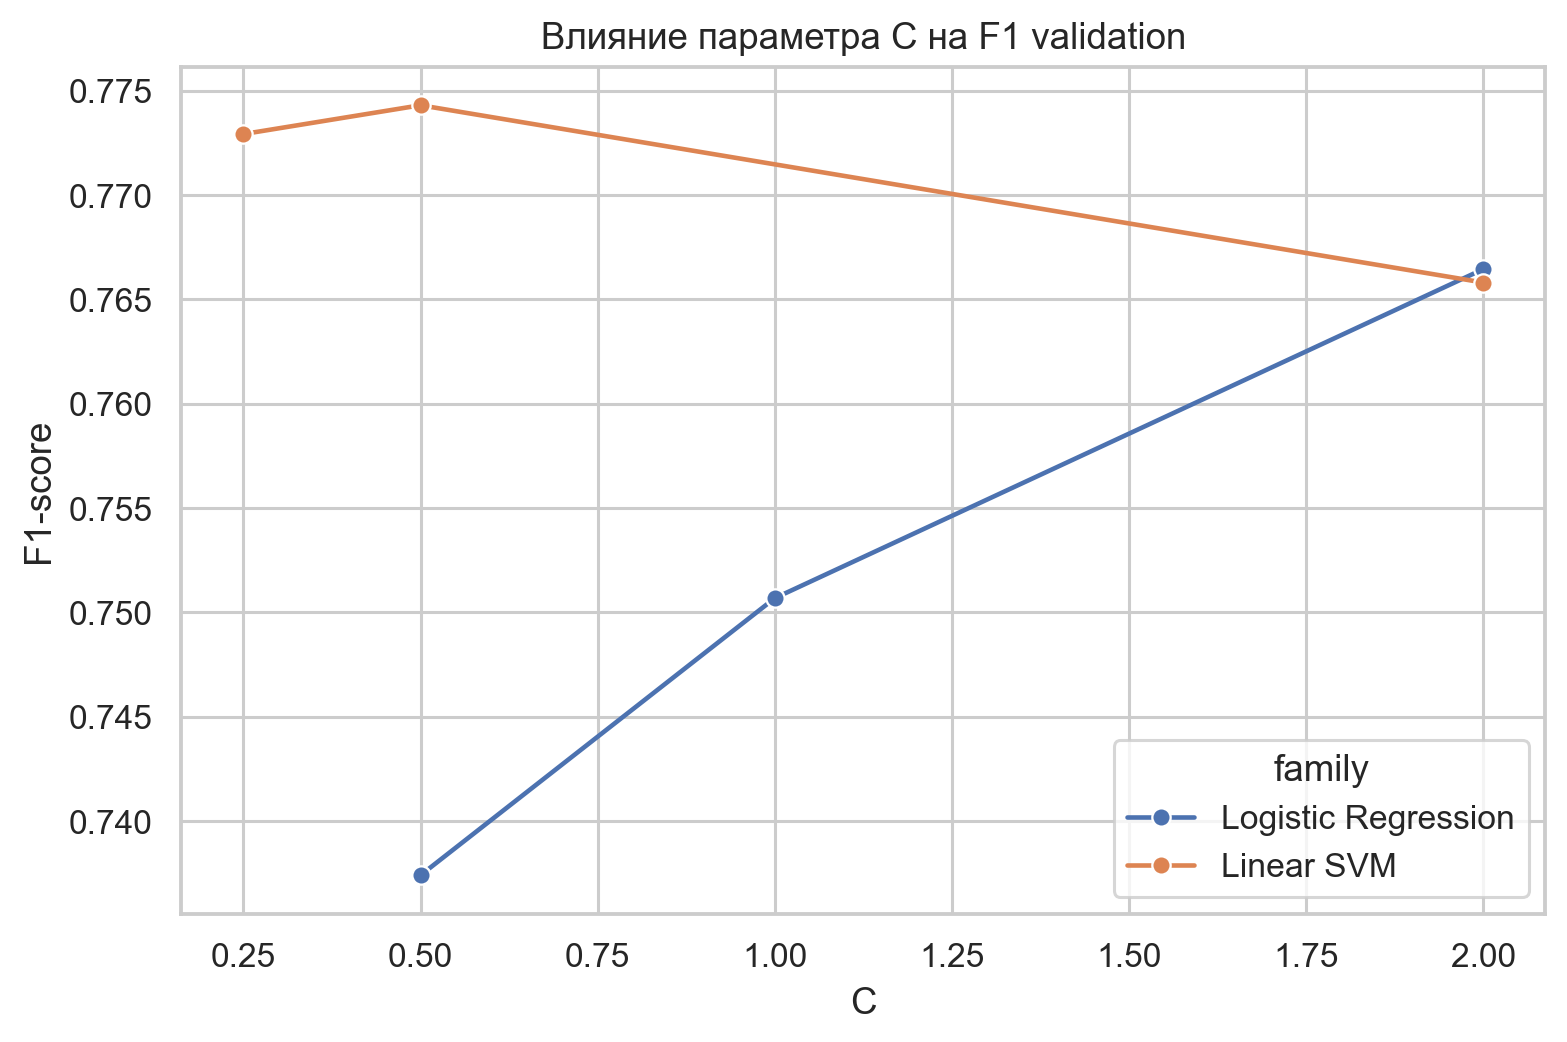

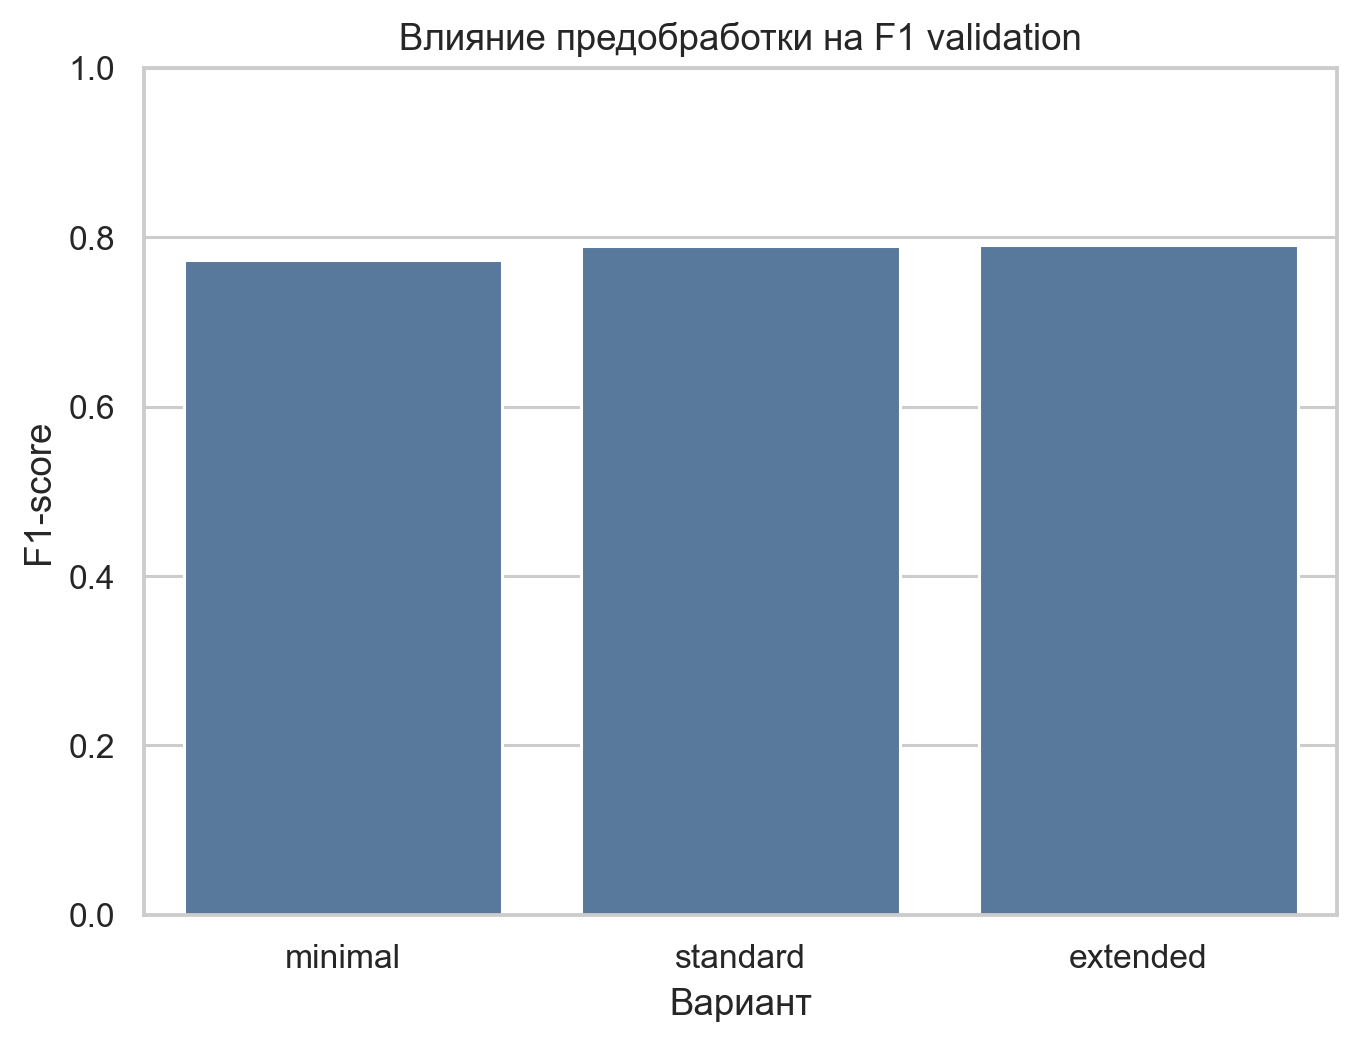

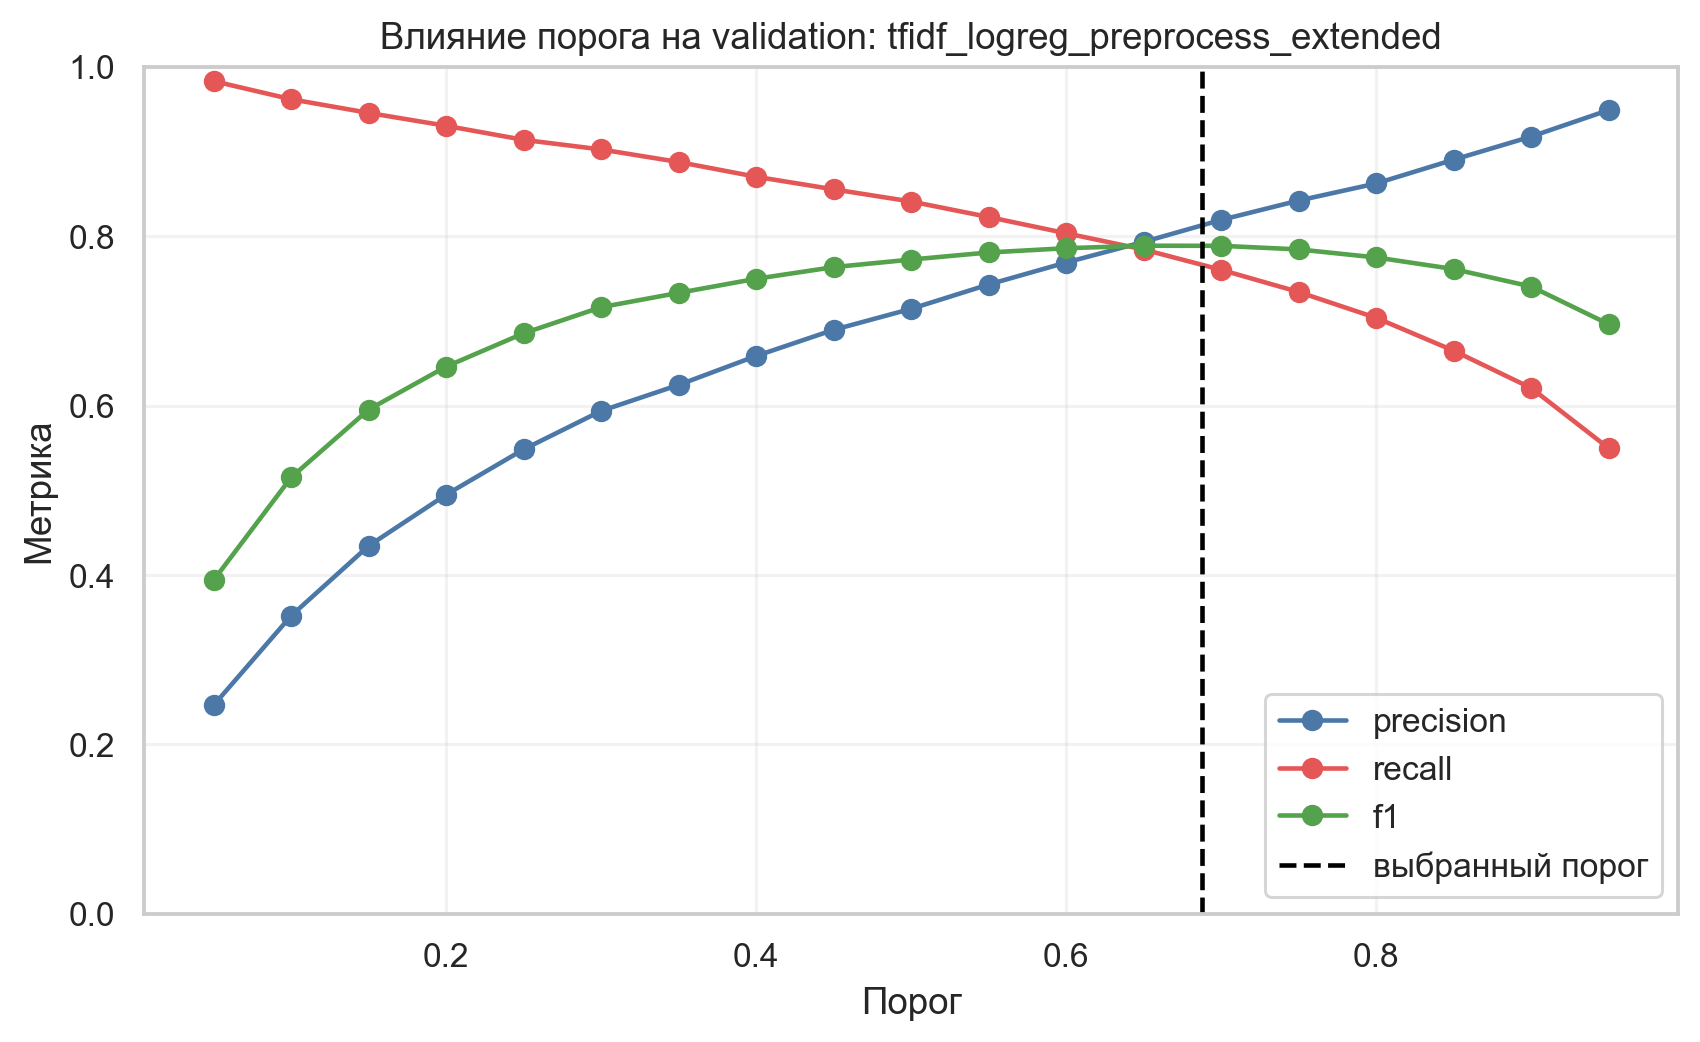

In [21]:
from toxicity.plots import plot_results

if not QUICK_MODE:
    classical_results.to_csv(paths.results_dir / "all_results.csv", index=False)
    plot_results(classical_results, paths.predictions_dir, paths.figures_dir)

    result_figures = [
        "results_f1_comparison.png",
        "results_precision_recall.png",
        "results_roc_curves.png",
        "results_pr_curves.png",
        "results_c_influence.png",
        "results_preprocessing_influence.png",
        "results_threshold_tradeoff.png",
    ]
    for filename in result_figures:
        figure_path = paths.figures_dir / filename
        if figure_path.exists():
            display(Image(filename=str(figure_path), width=760))
else:
    print("Quick-профиль не перезаписывает итоговые графики полного исследования.")

## 17. Анализ ошибок

Рассматриваются False Positive и False Negative. Для каждого примера сохраняются истинная метка, прогноз, оценка модели, длина и короткий фрагмент. Эвристические категории (`negation`, `masked_word`, `short`, `long` и др.) описывают наблюдаемый признак текста, но не объявляются доказанной внутренней причиной решения модели.

In [22]:
from toxicity.error_analysis import build_error_analysis

error_tables = {}
if not QUICK_MODE:
    for model_name in ("tfidf_logistic_regression", "tfidf_linear_svm"):
        prediction_path = paths.predictions_dir / f"{model_name}_test_predictions.csv"
        error_tables[model_name] = build_error_analysis(
            prediction_path,
            paths.results_dir / f"error_analysis_{model_name}.csv",
            extra_labels=frame,
        )

    selected_errors = error_tables["tfidf_logistic_regression"]
    balanced_examples = pd.concat(
        [
            selected_errors[selected_errors["error_type"] == "FP"].head(6),
            selected_errors[selected_errors["error_type"] == "FN"].head(6),
        ],
        ignore_index=True,
    )
    display(
        balanced_examples[
            ["error_type", "toxic", "prediction", "score", "heuristic_categories", "excerpt"]
        ]
    )
else:
    print("Детальный анализ ошибок выполняется только для полного профиля.")

,error_type,toxic,prediction,score,heuristic_categories,excerpt


### 17.1. Структура ошибок по наблюдаемым признакам

Сводка помогает увидеть, какие типы текстов встречаются среди ошибок чаще, но не заменяет качественное чтение примеров и не устанавливает причинность.

In [23]:
if not QUICK_MODE:
    category_counts = (
        selected_errors.assign(
            category=selected_errors["heuristic_categories"].fillna("other").str.split("|")
        )
        .explode("category")
        .groupby(["error_type", "category"])
        .size()
        .rename("count")
        .reset_index()
        .sort_values(["error_type", "count"], ascending=[True, False])
    )
    display(category_counts.groupby("error_type", group_keys=False).head(10))

    confusion_columns = ["test_tn", "test_fp", "test_fn", "test_tp"]
    display(primary_results.set_index("model")[confusion_columns].astype(int))

,error_type,category,count
0,false_negative,implicit_or_other,9
1,false_negative,negation,5
3,false_negative,negation;masked_word,4
5,false_negative,negation;profanity,2
6,false_negative,profanity,2
2,false_negative,negation;long,1
4,false_negative,negation;masked_word;short,1
7,false_negative,profanity;short,1
8,false_positive,implicit_or_other,9
10,false_positive,negation,4


,test_tn,test_fp,test_fn,test_tp
model,,,,
bow_multinomial_nb,21083,559,759,1535
tfidf_logistic_regression,21137,505,522,1772
tfidf_linear_svm,21233,409,592,1702


## 18. DistilBERT: реализация и вычислительный статус

`src/toxicity/bert.py` реализует собственный fine-tuning `distilbert-base-uncased`: токенизацию, усечение, динамический padding и attention masks, обучение головы и энкодера, validation, выбор лучшей checkpoint, сохранение модели и получение вероятностей после softmax.

Готовый классификатор токсичности не используется. Обучение запускается только при `RUN_BERT=True`, поскольку оно скачивает веса и требует значительно больше памяти и времени.

In [24]:
bert_environment = pd.DataFrame(
    [
        {"компонент": module, "доступен": importlib.util.find_spec(module) is not None}
        for module in ("torch", "transformers", "datasets", "accelerate")
    ]
)
display(bert_environment)
display(pd.DataFrame([config["bert"]]).T.rename(columns={0: "значение"}))

,компонент,доступен
0,torch,False
1,transformers,False
2,datasets,False
3,accelerate,False


,значение
model_name,distilbert-base-uncased
max_length,256
epochs,2
learning_rate,0.00002
train_batch_size,16
eval_batch_size,32
gradient_accumulation_steps,1
weight_decay,0.01
warmup_ratio,0.1
max_train_samples,None


In [25]:
if RUN_BERT:
    missing = bert_environment.loc[~bert_environment["доступен"], "компонент"].tolist()
    if missing:
        raise RuntimeError("Для BERT не установлены зависимости: " + ", ".join(missing))

    from toxicity.bert import run_bert_training
    from toxicity.plots import plot_bert_history

    bert_results = run_bert_training(
        splits,
        config,
        paths.results_dir,
        paths.models_dir,
        paths.predictions_dir,
        variant_name=BERT_VARIANT,
    )
    plot_bert_history(paths.results_dir / f"{BERT_VARIANT}_history.json", paths.figures_dir)
    display(bert_results)
else:
    print("DistilBERT не запущен: RUN_BERT=False. Это явно отражается в выводах и отчёте.")

DistilBERT не запущен: RUN_BERT=False. Это явно отражается в выводах и отчёте.


## 19. Фактический итог исследования

Итог формируется непосредственно из таблицы метрик, поэтому числа в выводе не вводятся вручную и не могут разойтись с экспериментом.

In [26]:
best_overall = classical_results.sort_values("test_f1", ascending=False).iloc[0]
summary_text = "\n".join(
    [
        "### Результат полного классического эксперимента",
        "",
        f"- Выполнено запусков: **{len(classical_results)}**.",
        f"- Лучшая конфигурация: **{best_overall['model']}**.",
        f"- Test Accuracy: **{best_overall['test_accuracy']:.4f}**.",
        f"- Test Precision: **{best_overall['test_precision']:.4f}**.",
        f"- Test Recall: **{best_overall['test_recall']:.4f}**.",
        f"- Test F1: **{best_overall['test_f1']:.4f}**.",
        f"- Test ROC-AUC: **{best_overall['test_roc_auc']:.4f}**.",
        f"- Test PR-AUC: **{best_overall['test_pr_auc']:.4f}**.",
        "",
        "Стандартная нормализация улучшила лучший F1 по сравнению с минимальной обработкой, "
        "а расширенная очистка не дала дополнительного выигрыша. Результаты DistilBERT "
        "не заявляются, пока fine-tuning фактически не выполнен.",
    ]
)
display(Markdown(summary_text))

### Результат полного классического эксперимента

- Выполнено запусков: **16**.
- Лучшая конфигурация: **tfidf_logreg_preprocess_standard**.
- Test Accuracy: **0.9606**.
- Test Precision: **0.8131**.
- Test Recall: **0.7642**.
- Test F1: **0.7879**.
- Test ROC-AUC: **0.9729**.
- Test PR-AUC: **0.8726**.

Стандартная нормализация улучшила лучший F1 по сравнению с минимальной обработкой, а расширенная очистка не дала дополнительного выигрыша. Результаты DistilBERT не заявляются, пока fine-tuning фактически не выполнен.

## 20. Пересборка курсовой работы

Word-документ читает сохранённые CSV, JSON и PNG. Следовательно, таблицы и численные выводы отчёта соответствуют фактическому запуску notebook.

In [27]:
from toxicity.report import build_report

if not QUICK_MODE:
    report_path = build_report(config, paths)
    print("Отчёт пересобран:", report_path)
else:
    print("Quick-профиль не пересобирает финальную курсовую.")

Отчёт пересобран: /Users/maksim/Documents/ChatGPT/курсовая по nlp/report/coursework.docx


## 21. Финальная проверка воспроизводимости

Проверяется наличие исходных данных, сохранённого split, результатов EDA, моделей, предсказаний, итоговой таблицы, нового графика порога и Word-документа. Последняя строка появляется только после успешного прохождения всех обязательных проверок.

In [28]:
required_outputs = [
    source_path,
    paths.results_dir / "environment.json",
    paths.results_dir / "eda_summary.json",
    paths.results_dir / "word_frequencies.csv",
    paths.processed_dir / "split_manifest.csv",
    paths.results_dir / ("classical_quick_results.csv" if QUICK_MODE else "classical_results.csv"),
]
if not QUICK_MODE:
    required_outputs += [
        paths.results_dir / "all_results.csv",
        paths.models_dir / "tfidf_logistic_regression.joblib",
        paths.predictions_dir / "tfidf_logistic_regression_test_predictions.csv",
        paths.figures_dir / "results_threshold_tradeoff.png",
        paths.results_dir / "error_analysis_tfidf_logistic_regression.csv",
        paths.report_dir / "coursework.docx",
    ]

status = pd.DataFrame(
    [
        {
            "artifact": str(path.relative_to(ROOT)) if path.is_relative_to(ROOT) else str(path),
            "exists": path.exists(),
            "bytes": path.stat().st_size if path.exists() else 0,
        }
        for path in required_outputs
    ]
)
display(status)
assert status["exists"].all(), "Не все обязательные артефакты созданы"
assert not classical_results["test_f1"].isna().any()
assert classical_results["test_f1"].between(0, 1).all()
print("ГОТОВО: notebook выполнен без ошибок, а обязательные артефакты проверены.")

,artifact,exists,bytes
0,data/raw/jigsaw-toxic-comment-classification-c...,True,68802655
1,artifacts/results/environment.json,True,493
2,artifacts/results/eda_summary.json,True,1001
3,artifacts/results/word_frequencies.csv,True,3703
4,data/processed/split_manifest.csv,True,3765886
5,artifacts/results/classical_results.csv,True,8117
6,artifacts/results/all_results.csv,True,8117
7,artifacts/models/tfidf_logistic_regression.joblib,True,2371535
8,artifacts/predictions/tfidf_logistic_regressio...,True,11276470
9,artifacts/figures/results_threshold_tradeoff.png,True,116949


ГОТОВО: notebook выполнен без ошибок, а обязательные артефакты проверены.
